# GKD checkpoint ladder — `20260805_ckptladder_160m`

End-to-end analysis of the **completed** pretraining-checkpoint ladder campaign
on PolyPythia-160M / **cat** (dog was not run). Behaviour run-set
`20260805_ckptladder_160m`; geometry run-set `20260805_ckptladder_geom_160m`;
Stage B concordance `20260727_slbreadth_160m`. Teachers share the behaviour
run-set id. Campaign finished (see `logs/CAMPAIGN_DONE` in the load cell).

This notebook is **read-only** on cached `results/` + `logs/` + geometry
`results/` / `parts/`. It does **not** retrain, does **not** re-run the 10k
cluster bootstrap, and does **not** write under `output_root`. Paths resolve
from `configs/paths/paths_local.yaml` via `analysis.setup.bootstrap`.

Pre-registration: `docs/PREREG_CKPT_LADDER.md`. Constants:
`subliminal_learning.campaign.ckpt_plan`. Claims math:
`subliminal_learning.campaign.ckpt_metrics`. Plan figures: plan §10.

**Run from the repo root:**
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/gkd_ckpt_ladder.ipynb` and run all cells top-to-bottom.

### Reading guide

- `ladder_delta.csv` is **already seed-aggregated** (`n_seeds_treatment` is 3 or 9).
  Do not re-average those rows as if they were leaves.
- **Never pool prompt sets into C1.** Primary endpoint is `test` / `prob`.
- **Never mix `slot_convention`.** Filter one convention before any mean.
  `post_block` for CKA/SSA/Procrustes (dial gate); `hidden_states` for trait
  coordinates (`TRAIT_SLOT_CONVENTION`).
- **Never pool animals.** This run is cat only.
- Quarantine rungs (step 512) are **excluded from C1** and **kept in C3**.
- `y = 0` on `SI_SS` by construction (gap vs the same-student-base anchor).
- `d_trait = 1 − trait_coordinate_similarity` is C1's x-axis. Do **not**
  substitute `d_geom = 1 − minibatch_cka`.
- `ladder_divergence.n_slots == 39` is 13 slots × 3 ftseeds (ftseed is not a
  group key in `attach_d_trait`). Do not treat that as 13.
- Coverage is **absent** from `ladder_weight_space.csv`; load per-leaf
  `first_step_coverage.jsonl` in memory (do not write a merged CSV).
- §16b is visualization only: it pivots `ladder_delta` / admission and loads
  per-leaf `training_metrics.jsonl` in memory. It does **not** invent a
  teacher×student *checkpoint* grid (none exists: every trained pair is
  same-rung). Blank init-grid cells are unrun, not 0.
- Each figure is followed by a **Reading this figure** cell: the question it
  answers, axes, how the metric is computed, the trend on *this* run, and
  what that does (and does not) support. Final claims are in **§17 Takeaways**.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Inventory & coverage vs plan |
| 1 | Provenance (init equality, dial gate, admission, flags) |
| 2 | Fig1 Divergence dial (`d_trait` / `d_geom` vs log step) |
| 3 | Fig2 Transfer gap (delta and `y` vs log step by cell) |
| 4 | Fig3 Money plot C1 (`y` vs `d_trait` + OLS from CSV) |
| 5 | Fig4 Emergence C3 |
| 6 | Fig5 Basis breakdown C4 |
| 7 | Fig6 Capability confound C5 |
| 8 | Fig7 Variance components |
| 9 | Fig8 Stage B concordance C6 |
| 10 | Fig9 Prompt-set robustness |
| 11 | Fig10 Self-drift C7 |
| 12 | Fig11 Probes C8a (UPOS + trait) |
| 13 | Fig12 Metric grading C8b |
| 14 | Fig13 Weight space C9 + Madl coverage |
| 15 | Fig14 Layer×layer CKA from parts shards |
| 16 | Extra views |
| 16b | Checkpoint-SL views (same-rung heatmaps; no T×S checkpoint grid) |
| 17 | Claims board + takeaways (from JSON + frames) |
| 18 | How to extend |

### Explicit exclusions

- Dog (`include_dog: false`); CCA (`include_cca: false`); behaviour `DI∩DS`
  (no family-swap / no cyclic-closure).
- Pile corpus perplexity (absent from the capability CSV).
- `results/similarity_layer_means.csv` (absent). Optional band means in §16
  are a **notebook aggregation** of existing per-slot rows, not a pipeline table.
- Merged `results/estimator_diagnostics.json` (absent). Fig1 floor + Fig14
  13×13 matrices are read **only** from `parts/p1__{convention}__*/`.
- `coverage` column in `ladder_weight_space.csv` (absent). Per-leaf jsonl in §14.
- GKD **in-training** `p_target` is **not** C8a: `ladder_probe_trajectories.csv`
  is UPOS `probe_grounding`. §16b loads per-leaf `training_metrics.jsonl` in
  memory via `load_gkd_probe_trajectories` (probe prompts ≠ C1 `test` set).
- Teacher×student **checkpoint** grid (teacher step ≠ student step): not on
  disk. The pairing generator emits same-rung pairs only. §16b uses the 7×7
  **init** grid instead (23/49 cells; blank = unrun, including all DI∩DS).
- Teacher adapter walk (teachers exist; this notebook does not open them).

### Metric cheat-sheet

Formulas match prereg §6, `ckpt_metrics`, and `cka.metrics`. **Do not** treat `d_geom` as `d_trait`. Values are theoretical ranges, not this run’s numbers (those print from CSVs below).

| ID | Answers | Values | Calculation | Example reading | Notes |
|---|---|---|---|---|---|
| `subliminal_delta` | Did GKD from this teacher raise target-animal preference above a matched **base-teacher** control? | Difference of two probabilities: theoretically (−1, 1), typically near 0. Not a percent of control. | `p_target_treatment − p_target_control` (`gkd_results_io.subliminal_delta`; Cloud SL). Primary `test` uses `prob`: mean over prompts of exact last-token p(`" cat"`) (`preference_prob_io`). `storytelling` uses `sample` (surface-form hit rate). Treatments averaged over ftseed; control matched on (animal, student init, gkd_tag, set). | `0` = no SL above control. `+0.02` = treatment puts 2 pp more probability on `" cat"` than the control. Negative = treatment *less* target-preferring than control. | Pairing-level in `ladder_delta.csv` (already seed-aggregated). C3 thresholds this on SI∩SS. Never compare raw `p_target` across rungs. |
| `y` | How much extra (or missing) SL does this pairing have vs the **same student**, same rung, same prompt set on SI∩SS? | Difference of two deltas: theoretically (−2, 2). Exactly `0` on SI∩SS. | `subliminal_delta(pair) − subliminal_delta(SI∩SS, same student init, same rung, same set)` (`ckpt_metrics.attach_y`). NaN if the anchor is missing — never silently 0. | `0` = this pairing matches the same-init student. `−0.05` = 5 pp *less* SL than that anchor (transfer gap). `+0.05` = 5 pp *more* than the anchor. | C1 response. Claims use `test`/`prob` only. C1 drops SI∩SS (family is NaN there) and admission-quarantine rungs. |
| `d_trait` | Do the two models disagree along the **trait axis** (cat-teacher vs base), even when neuron indices do not correspond? | [0, 1] | `1 − trait_coordinate_similarity`. Last-token activations (`hidden_states`) projected onto **each model’s own** unit `diff_vector` (mean_teacher − mean_base). Similarity = squared Pearson of the two `[n]` coordinate vectors (`cka.metrics.trait_coordinate_similarity` = linear CKA at k=1). `attach_d_trait` averages slots (this dump: `n_slots=39` = 13 slots × 3 ftseeds). | `0` = trait coordinates match **or** are exact sign-flips (squaring). `1` = uncorrelated. `0.2` = similarity 0.8. | **C1 x-axis.** Valid on `BASIS_BROKEN`. Never substitute `d_geom`. A null on global CKA is preregistered (Okatan; Ding). |
| `d_geom` | How different are two **untrained** bases’ full residual representations (example-similarity structure)? | Nominally [0, 1]; unbiased HSIC_1 can push CKA slightly outside, so `d_geom` can too. | `1 − minibatch_cka`. Linear CKA with unbiased HSIC_1 (Nguyen / Raghu: 10,240 examples, batch 1,024, 20 repeats) on Pile-pool last-token activations. P1; no teacher. | `0` = CKA=1 (same up to orthogonal transform + isotropic scale). `1` = CKA=0 (unrelated). Dial gate requires Ladder-B span ≥ 0.10. | **Dial-gate x only**, not C1. Gate uses `post_block`. Early rungs sit near the random-init floor (Kornblith §6.2). |
| `ssa` | How far apart are the top principal subspaces of two representations that **share a neuron basis**? | [0, 90] degrees in CSVs. C4 uses value/90 ∈ [0, 1]. | Mean of the k=`SSA_K=10` principal angles (degrees) between top-10 PCA subspaces (`subspace_angles_topk` + `ssa_reduce="mean"`). Deviation from PolyPythias: they apply SSA to **probe-weight** subspaces; this campaign uses PCA of raw activations. | `0°` = subspaces coincide. `90°` = orthogonal. PolyPythias consecutive-ckpt SSA rises ~step 10³, plateaus ~10⁴, falls toward ~20° (literature *shape* for C7, not a threshold). | Shared-basis only (data-seed / lineage). Not defined on `BASIS_BROKEN`. C4 per-coordinate fallback (`shared_basis_subspace_cka` absent). |
| `perplexity_ratio` | Did GKD degrade the student’s language-modeling capability vs **its own base** at this revision? | (0, ∞). `1` = unchanged. | Token-weighted Pile PPL of the trained student / PPL of that student’s untrained base: `exp(Σ NLL / Σ tokens)` on `pile_reference_bank`, fp32 softmax. From `sdf_capability_summary.json`, joined onto `ladder_delta`. | `1.0` = same PPL as base. `2.0` = twice the PPL (worse). Ratio `> 5.0` is the leaf quarantine bound (`QUARANTINE_PPL_RATIO_MAX`). | C5: per-rung abs Spearman(y, ratio) ≥ 0.5 → `quarantine_confound`. Not P1b LAMBADA PPL. |
| `probe_accuracy` | Is this slot’s representation **linearly readable** for syntax (UPOS) — is the geometry functionally used? | [0, 1] | Logistic regression on frozen activations, 80/20 stratified split, held-out accuracy (`cka.probes.fit_linear_probe`). Task = UPOS, UD English-EWT, 17 tags (P1c). | Near `1` = PoS is linearly decodable. Near the majority-class rate (not 50%; 17 tags) = not linearly readable. C8b Spearman of geometry metrics vs this (Ding et al.). | `ladder_probe_trajectories.csv` is this UPOS table, **not** GKD in-training `p_target` probes. Do not mix `slot_convention`. |
| `coverage` | At the **first** GKD step, does the student already step in the teacher’s LoRA displacement direction (Madl body-channel screen)? | Theoretically [−1, 1] when defined. Omitted (not 0) on broken basis. | `cos(student first-step ΔW, teacher merged LoRA ΔW)` on overlapping keys, times `‖ΔW_restricted‖ / ‖ΔW_full‖` (`cka.weight_space_io.coverage`; Madl arXiv:2606.22019). Shared-weight-init only. | `1` = first step parallel to the teacher displacement. `0` = orthogonal. Negative = opposite. `skip_reason=basis_broken` on DI∩SS is **not** a coverage of 0. | jsonl glob only (`first_step_coverage.jsonl`); **not** a column of `ladder_weight_space.csv`. C9 shared-init pairs. |
| `frankle_barrier` | Are two shared-init checkpoints linearly mode-connected, or is there a loss bump on the line between them? | ≥ 0 (CE nats/token above the chord). | Interpolate θ(α)=(1−α)θ_A + α θ_B at α ∈ {0, 0.25, 0.5, 0.75, 1}. Barrier = max_α [L(α) − ((1−α)L(0)+α L(1))] (`barrier_from_curve`; Entezari/Ferbach form of Frankle arXiv:1912.05671 §2). L = per-token CE on the Pile bank, **not** trait prompts. | `0` = no barrier (interpolants never worse than the chord). `0.1` = peak interpolant is 0.1 nats/token above the chord. | 8 SI∩DS pairings × rungs 2000, 16000, 143000. SI∩SS would be identically 0. Skipped on `BASIS_BROKEN`. |


## Setup


In [1]:
from __future__ import annotations

import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import ckpt_plan as plan
from subliminal_learning.campaign.ckpt_metrics import (
    FAMILY_OF_CELL,
    filter_primary,
    with_init_labels,
    attach_family_undirected,
)
from subliminal_learning.campaign.ckpt_pairs import (
    Cell,
    cell_of,
    ladder_pairs,
    N_CROSSED_ANCHOR_PAIRS_DEFAULT,
    N_LADDER_PAIRS_DEFAULT,
)
from subliminal_learning.cka.pairing import canonical_label, split_revision
from subliminal_learning.cka.results_io import (
    read_result_table,
    require_single_convention,
    revision_step,
    similarity_results_dir,
    similarity_run_dir,
)
from subliminal_learning.gkd.layout import GKD_STUDENTS_SUBDIR

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)

# Knobs for §18 (re-run downstream cells after changing).
DEEP_SLOT: int | None = None  # None = mean over slots 0..12
CONVENTION = plan.SLOT_CONVENTION  # post_block (dial gate / Angela)
TRAIT_CONVENTION = plan.TRAIT_SLOT_CONVENTION  # hidden_states
PROMPT_SET = plan.PRIMARY_PROMPT_SET  # test

# Match notebooks/cka_analysis.ipynb: data/stream red, weight/init blue.
FAMILY_COLORS = {
    "data": "#d62728",    # stream, SI∩DS (shared init)
    "weight": "#1f77b4",  # init, DI∩SS (shared data order)
}
CELL_COLORS = {
    "SI_SS": "#4daf4a",
    "SI_DS": "#d62728",
    "DI_SS": "#1f77b4",
}
CELL_LABELS = {
    "SI_SS": "SI∩SS (anchor)",
    "SI_DS": "SI∩DS (stream / data)",
    "DI_SS": "DI∩SS (init / weight)",
}

TREE = OUTPUT_ROOT / GKD_STUDENTS_SUBDIR / plan.RUN_SET_ID
RES = TREE / "results"
LOGS = TREE / "logs"
GEOM_TREE = similarity_run_dir(OUTPUT_ROOT, plan.GEOM_RUN_SET_ID)
GEOM_RES = similarity_results_dir(OUTPUT_ROOT, plan.GEOM_RUN_SET_ID)
GEOM_PARTS = GEOM_TREE / "parts"

assert TREE.exists(), f"missing behaviour tree: {TREE}"
assert RES.exists(), f"missing results/: {RES}"
assert LOGS.exists(), f"missing logs/: {LOGS}"
assert GEOM_RES.exists(), f"missing geometry results/: {GEOM_RES}"
assert "/mnt/ssd-1/" not in str(OUTPUT_ROOT), (
    f"refusing slow SSD-1 output_root: {OUTPUT_ROOT}"
)
if TREE.is_symlink():
    print("WARNING: TREE is a symlink →", TREE.resolve())

print("ROOT        :", ROOT)
print("OUTPUT_ROOT :", OUTPUT_ROOT)
print("TREE        :", TREE)
print("RES         :", RES)
print("LOGS        :", LOGS)
print("GEOM_RES    :", GEOM_RES)
print("GEOM_PARTS  :", GEOM_PARTS)
print("RUN_SET     :", plan.RUN_SET_ID)
print("GEOM_RUN    :", plan.GEOM_RUN_SET_ID)
print("STAGE_B     :", plan.STAGE_B_RUN_SET_ID)
print("teacher tag :", plan.TEACHER_PARAM_TAG_LORA)
print("student tag :", plan.STUDENT_GKD_TAG)
print("inits       :", plan.INITS)
print("animals     :", plan.ANIMALS)
print("Ladder G    :", plan.LADDER_G)
print("Ladder B    :", plan.LADDER_B)
print("prompt sets :", plan.EVAL_PROMPT_SETS)
print("primary     :", plan.PRIMARY_PROMPT_SET, plan.PRIMARY_SCORING)
print("conventions :", CONVENTION, "(CKA/SSA) /", TRAIT_CONVENTION, "(trait)")
print("DEEP_SLOT   :", DEEP_SLOT, "| PROMPT_SET:", PROMPT_SET)


def scope(df: pd.DataFrame, note: str = "") -> None:
    """Print a compact SCOPE line (does not assume teacher-sweep columns)."""
    bits = [f"n={len(df)}"]
    for col in (
        "animal", "set", "cell", "family", "step", "slot", "slot_convention",
        "metric", "pairing_index", "init", "task",
    ):
        if col in df.columns:
            bits.append(f"{col}={df[col].nunique(dropna=False)}")
    line = "SCOPE: " + " | ".join(bits)
    if note:
        line += f" | {note}"
    print(line)


def step_x(step) -> float:
    """Log-x helper: plot step 0 at 0.5 so it is visible on a log axis."""
    s = float(step)
    return 0.5 if s <= 0 else s


def add_step_x(df: pd.DataFrame, src: str = "step") -> pd.DataFrame:
    out = df.copy()
    out["x"] = [step_x(v) for v in out[src]]
    return out


def claim_record(cid: str) -> dict:
    for rec in CLAIMS["claims"]:
        if rec["claim"] == cid:
            return rec
    raise KeyError(cid)


def one_convention(df: pd.DataFrame, name: str, convention: str) -> pd.DataFrame:
    """Filter to `convention` and refuse a mixed frame."""
    out = df[df["slot_convention"].astype(str) == convention].copy()
    require_single_convention(out, name)
    return out


def maybe_slot(df: pd.DataFrame) -> pd.DataFrame:
    if DEEP_SLOT is None or "slot" not in df.columns:
        return df
    return df[df["slot"].astype(int) == int(DEEP_SLOT)].copy()


def primary_frame(df: pd.DataFrame) -> pd.DataFrame:
    """Primary endpoint using the PROMPT_SET knob (C1 pipeline tables stay test)."""
    return filter_primary(df, prompt_set=PROMPT_SET, scoring=plan.PRIMARY_SCORING)


def iter_p1_diagnostics(convention: str):
    """Yield (path, payload) for P1 estimator shards of one convention."""
    pattern = f"p1__{convention}__*/estimator_diagnostics.json"
    for path in sorted(GEOM_PARTS.glob(pattern)):
        yield path, json.loads(path.read_text())


ROOT        : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning
OUTPUT_ROOT : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
TREE        : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260805_ckptladder_160m
RES         : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260805_ckptladder_160m/results
LOGS        : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260805_ckptladder_160m/logs
GEOM_RES    : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/similarity/20260805_ckptladder_geom_160m/results
GEOM_PARTS  : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/similarity/20260805_ckptladder_geom_160m/parts
RUN_SET     : 20260805_ckptladder_160m
GEOM_RUN    : 20260805_ckptladder_geom_160m
STAGE_B     : 20260727_slbreadth_160m
teacher tag : ep5_lr5e-5_r128a128
student tag : lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
inits       : ('original', 'data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weigh

## Load artifacts

One cell: behaviour CSVs (pandas; **not** in `RESULT_TABLES`), geometry tables
via `cka.results_io.read_result_table` (schema-checked), `claims.json`, and
campaign log JSONs. Geometry CSVs that are not in `RESULT_TABLES` are loaded
with pandas or noted absent.


In [2]:
def _read_csv(name: str) -> pd.DataFrame:
    path = RES / name
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def _read_json(dirpath: Path, name: str) -> dict:
    path = dirpath / name
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text())


BEHAVIOUR_CSV = {
    "delta": plan.RESULTS_DELTA_CSV,
    "agg": plan.RESULTS_DELTA_AGG_CSV,
    "div": plan.RESULTS_DIVERGENCE_CSV,
    "cap": plan.RESULTS_BASE_CAPABILITY_CSV,
    "c4": plan.RESULTS_BASIS_BREAKDOWN_CSV,
    "c3": plan.RESULTS_EMERGENCE_CSV,
    "grade": plan.RESULTS_METRIC_GRADING_CSV,
    "q": plan.RESULTS_QUARANTINE_CSV,
    "reg": plan.RESULTS_REGRESSION_CSV,
    "repl": plan.RESULTS_REPLICATION_MAP_CSV,
    "var": plan.RESULTS_VARIANCE_COMPONENTS_CSV,
    "wspace": plan.RESULTS_WEIGHT_SPACE_CSV,
    "drift": plan.RESULTS_SELF_DRIFT_CSV,
    "probe": plan.RESULTS_PROBE_CSV,
}

for key, name in BEHAVIOUR_CSV.items():
    assert (RES / name).exists(), f"missing {RES / name}"

delta = _read_csv(plan.RESULTS_DELTA_CSV)
agg = _read_csv(plan.RESULTS_DELTA_AGG_CSV)
div = _read_csv(plan.RESULTS_DIVERGENCE_CSV)
cap = _read_csv(plan.RESULTS_BASE_CAPABILITY_CSV)
c4_tab = _read_csv(plan.RESULTS_BASIS_BREAKDOWN_CSV)
c3_tab = _read_csv(plan.RESULTS_EMERGENCE_CSV)
grade = _read_csv(plan.RESULTS_METRIC_GRADING_CSV)
quarantine = _read_csv(plan.RESULTS_QUARANTINE_CSV)
reg = _read_csv(plan.RESULTS_REGRESSION_CSV)
repl = _read_csv(plan.RESULTS_REPLICATION_MAP_CSV)
var = _read_csv(plan.RESULTS_VARIANCE_COMPONENTS_CSV)
wspace = _read_csv(plan.RESULTS_WEIGHT_SPACE_CSV)
drift = _read_csv(plan.RESULTS_SELF_DRIFT_CSV)
probe_upos = _read_csv(plan.RESULTS_PROBE_CSV)

CLAIMS = _read_json(RES, plan.RESULTS_CLAIMS_JSON)
STATE = _read_json(LOGS, plan.CAMPAIGN_STATE_FILE)
DIAL = _read_json(LOGS, plan.DIAL_GATE_REPORT)
INIT_EQ = _read_json(LOGS, plan.INIT_EQUALITY_LADDER_REPORT)
PREFLIGHT = _read_json(LOGS, plan.PREFLIGHT_REPORT)
ADMISSION = _read_json(LOGS, plan.TEACHER_ADMISSION_REPORT)

done_path = LOGS / plan.CAMPAIGN_DONE_FILE
assert done_path.exists(), f"missing {done_path}"
DONE_TEXT = done_path.read_text().strip()
assert "finished" in DONE_TEXT.lower() or "CAMPAIGN_DONE" in plan.CAMPAIGN_DONE_FILE
print("CAMPAIGN_DONE:", DONE_TEXT)

GEOM_TABLES = {
    "similarity_pairs": None,
    "probe_grounding": None,
    "probe_trait": None,
    "trait_vector_stability": None,
    "self_drift": None,
    "weight_space": None,
}
for name in list(GEOM_TABLES):
    path = GEOM_RES / f"{name}.csv"
    if not path.exists():
        print(f"ABSENT geometry table: {name}")
        continue
    GEOM_TABLES[name] = read_result_table(GEOM_RES, name)

sim = GEOM_TABLES["similarity_pairs"]
probe_grounding = GEOM_TABLES["probe_grounding"]
probe_trait = GEOM_TABLES["probe_trait"]
trait_stab = GEOM_TABLES["trait_vector_stability"]

layer_means_path = GEOM_RES / "similarity_layer_means.csv"
print(
    "ABSENT similarity_layer_means.csv"
    if not layer_means_path.exists()
    else f"unexpected: {layer_means_path} exists"
)
merged_diag = GEOM_RES / "estimator_diagnostics.json"
print(
    "ABSENT merged estimator_diagnostics.json (use parts/ shards)"
    if not merged_diag.exists()
    else f"unexpected: {merged_diag} exists"
)
print("coverage column in weight_space:", "coverage" in wspace.columns)
print("Pile task in capability:", [t for t in cap["task"].unique() if "pile" in str(t).lower()])

print("resolved RES files:")
for p in sorted(RES.iterdir()):
    if p.is_file():
        print(f"  {p.name:32s} {p.stat().st_size:9d} B")


CAMPAIGN_DONE: campaign 20260805_ckptladder_160m finished 2026-08-13T06:57:00Z
ABSENT similarity_layer_means.csv
ABSENT merged estimator_diagnostics.json (use parts/ shards)
coverage column in weight_space: False
Pile task in capability: []
resolved RES files:
  claims.json                          15104 B
  ladder_base_capability.csv           68017 B
  ladder_basis_breakdown.csv             880 B
  ladder_delta.csv                    362072 B
  ladder_delta_agg.csv                 10726 B
  ladder_divergence.csv               507895 B
  ladder_emergence.csv                   981 B
  ladder_metric_grading.csv              365 B
  ladder_probe_trajectories.csv      1962860 B
  ladder_quarantine.csv                 1489 B
  ladder_regression.csv                  481 B
  ladder_replication_map.csv           48537 B
  ladder_self_drift.csv               929315 B
  ladder_variance_components.csv         872 B
  ladder_weight_space.csv              16739 B


## 0. Inventory & coverage

**What this measures.** Disk vs plan: 23 pairings, 12 Ladder-B rungs, 20
Ladder-G rungs, 4 prompt sets, 7 inits, replication map, admitted vs
quarantined rungs. Fail loud if the primary `test`/`prob` frame is empty.


In [3]:
pairs = ladder_pairs()
print("plan N_LADDER_PAIRS_DEFAULT", N_LADDER_PAIRS_DEFAULT, "live", len(pairs))
print("cells in pairing set:", Counter(str(p.cell) for p in pairs))
print("DI_DS in pairing set:", sum(p.cell == Cell.DI_DS for p in pairs))
print("crossed-anchor pairings (default):", N_CROSSED_ANCHOR_PAIRS_DEFAULT)
print("campaign_state.options:", STATE.get("options"))
print("claims pairing_flags:", CLAIMS.get("pairing_flags"))
print("claims n_pairings:", CLAIMS.get("n_pairings"))
print("admitted_rungs:", CLAIMS.get("admitted_rungs"))
print("quarantined_rungs:", CLAIMS.get("quarantined_rungs"))

prim = primary_frame(delta)
scope(delta, "ladder_delta all sets")
scope(prim, "PRIMARY test/prob")
if prim.empty:
    raise RuntimeError("primary test/prob frame is empty — cannot score C1–C9")

print("animals:", sorted(delta["animal"].dropna().unique().tolist()))
print("sets × scoring:\n", delta.groupby(["set", "scoring"]).size())
print("cells:", delta["cell"].value_counts(dropna=False).to_dict())
print("family:", delta["family"].value_counts(dropna=False).to_dict())
print("B rungs in delta:", sorted(int(s) for s in delta["step"].unique()))
print("test rows:", len(prim), "expected 23×12 =", 23 * 12)
print("SI_SS y all ~0:", bool(np.allclose(prim.loc[prim["cell"] == "SI_SS", "y"], 0.0)))
print("n_seeds_treatment:", delta["n_seeds_treatment"].value_counts().to_dict())
print("div slot_convention:", div["slot_convention"].value_counts().to_dict())
print("div n_slots:", div["n_slots"].value_counts().to_dict())
print("agg shape (C1 fit frame):", agg.shape, "n_leaves:", agg["n_leaves"].unique().tolist())
print("agg rungs:", sorted(int(s) for s in agg["step"].unique()))
print("replication rows:", len(repl), "pairings:", repl["pairing_index"].nunique())
print("crossed flag:", repl["is_crossed_anchor"].value_counts().to_dict())
print("crossed rungs:", sorted(int(s) for s in repl.loc[repl["is_crossed_anchor"], "step"].unique()))
print("crossed n pairings:", repl.loc[repl["is_crossed_anchor"], "pairing_index"].nunique())

if sim is None:
    raise RuntimeError("similarity_pairs.csv missing")
scope(sim, "similarity_pairs")
print("sim metrics:", sim["metric"].value_counts().to_dict())
print("sim conventions:", sim["slot_convention"].value_counts().to_dict())
print("sim pairing_group:", sim["pairing_group"].value_counts(dropna=False).to_dict())
print("sim G rungs:", sorted(int(s) for s in sim["step"].unique()))
print("P1 untrained (animal NA) rows:", int(sim["animal"].isna().sum()))
print("cap tasks:", cap["task"].value_counts().to_dict())
print("cap metrics:", cap["metric"].value_counts().to_dict())
print("wspace metrics:", wspace["metric"].unique().tolist())
print("wspace coverage col present:", "coverage" in wspace.columns)
print("quarantine tiers:", quarantine["tier"].unique().tolist())

print("SCOPE summary: 23 pairings | 12 B rungs | 20 G rungs | 4 sets | 7 inits")
print(
    "  replication", len(repl),
    "| C1 admitted rungs", len(CLAIMS["admitted_rungs"]),
    "| C1 quarantined", CLAIMS["quarantined_rungs"],
)


plan N_LADDER_PAIRS_DEFAULT 23 live 23
cells in pairing set: Counter({'SI_DS': 8, 'DI_SS': 8, 'SI_SS': 7})
DI_DS in pairing set: 0
crossed-anchor pairings (default): 15
campaign_state.options: {'include_family_swap': False, 'include_cyclic_closure': False, 'include_dog': False, 'include_cca': False}
claims pairing_flags: {'include_family_swap': False, 'include_cyclic_closure': False}
claims n_pairings: 23
admitted_rungs: [1000, 2000, 4000, 8000, 16000, 32000, 48000, 64000, 96000, 128000, 143000]
quarantined_rungs: [512]
SCOPE: n=1104 | animal=1 | set=4 | cell=3 | family=3 | step=12 | pairing_index=23 | ladder_delta all sets
SCOPE: n=276 | animal=1 | set=1 | cell=3 | family=3 | step=12 | pairing_index=23 | PRIMARY test/prob
animals: ['cat']
sets × scoring:
 set           scoring
favorite      prob       276
off_topic     prob       276
storytelling  sample     276
test          prob       276
dtype: int64
cells: {'SI_DS': 384, 'DI_SS': 384, 'SI_SS': 336}
family: {'data': 384, 'weight': 

## 1. Provenance

**What this measures.** P0 init-equality at `step0`, P1→P2 dial gate, teacher
admission (ok / advisory) as a rung×init heatmap, and campaign flags. Numbers
come from the log JSONs in the next cell — not from this markdown.


init_equality verdict: as_expected revision: step0


,a,b,n_mismatched,n_tensors,equal,expected_equal,as_expected
0,original,data-seed1,0,148,True,True,True
1,original,data-seed2,0,148,True,True,True
2,original,data-seed3,0,148,True,True,True
3,original,weight-seed1,50,148,False,False,True
4,original,weight-seed2,50,148,False,False,True
5,original,weight-seed3,50,148,False,False,True
6,data-seed1,data-seed2,0,148,True,True,True
7,data-seed1,data-seed3,0,148,True,True,True
8,data-seed1,weight-seed1,50,148,False,False,True
9,data-seed1,weight-seed2,50,148,False,False,True


original vs data-seed mismatched/n: [{'b': 'data-seed1', 'n_mismatched': 0, 'n_tensors': 148}, {'b': 'data-seed2', 'n_mismatched': 0, 'n_tensors': 148}, {'b': 'data-seed3', 'n_mismatched': 0, 'n_tensors': 148}]
original vs weight-seed mismatched/n: [{'b': 'weight-seed1', 'n_mismatched': 50, 'n_tensors': 148}, {'b': 'weight-seed2', 'n_mismatched': 50, 'n_tensors': 148}, {'b': 'weight-seed3', 'n_mismatched': 50, 'n_tensors': 148}]

dial_gate passed: True measure: d_geom = 1 - minibatch_cka
  step0_anchor: passed=True value=None thr=1e-06 | identity-like: ['data-seed1', 'data-seed2', 'data-seed3']; distinguishable weight-seed: ['weight-seed1', 'weight-seed2', 'weight-seed3']
  divergence_span: passed=True value=0.39938638241693397 thr=0.1 | d_geom = 1 - minibatch_cka spans 0.3994 over 12 Ladder-B rungs
  family_separation: passed=True value=0.053946091569452015 thr=0.05 | max |SI∩DS - DI∩SS| = 0.0539 over 12 rungs

admission tier_counts: {'ok': 75, 'advisory': 9, 'quarantine': 0} ok_rungs

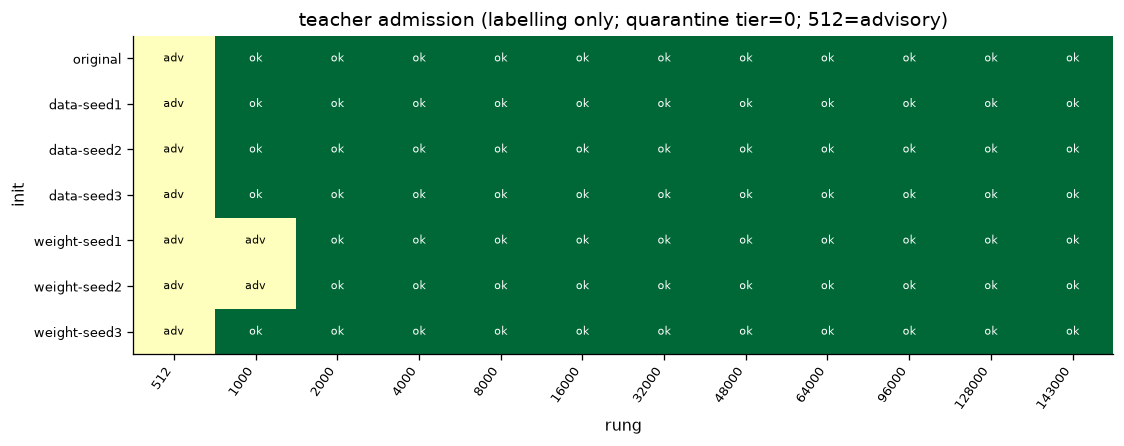

campaign flags: {'include_family_swap': False, 'include_cyclic_closure': False, 'include_dog': False, 'include_cca': False}
preflight init_equality_verdict: as_expected
preflight slot_convention: {'slot_convention': 'post_block', 'trait_slot_convention': 'hidden_states', 'geometry_conventions': ['post_block', 'hidden_states'], 'prereg': 'docs/PREREG_CKPT_LADDER.md'}


In [4]:
print("init_equality verdict:", INIT_EQ.get("verdict"), "revision:", INIT_EQ.get("revision"))
eq_rows = []
for rec in INIT_EQ.get("pairs", []):
    a, b = rec["pair"]
    eq_rows.append(
        {
            "a": a,
            "b": b,
            "n_mismatched": rec["n_mismatched"],
            "n_tensors": rec["n_tensors"],
            "equal": rec["equal"],
            "expected_equal": rec["expected_equal"],
            "as_expected": rec["as_expected"],
        }
    )
eq = pd.DataFrame(eq_rows)
display(eq)
orig_data = eq[(eq["a"] == "original") & (eq["b"].str.startswith("data-seed"))]
orig_w = eq[(eq["a"] == "original") & (eq["b"].str.startswith("weight-seed"))]
print("original vs data-seed mismatched/n:", orig_data[["b", "n_mismatched", "n_tensors"]].to_dict("records"))
print("original vs weight-seed mismatched/n:", orig_w[["b", "n_mismatched", "n_tensors"]].to_dict("records"))

print("\ndial_gate passed:", DIAL.get("passed"), "measure:", DIAL.get("scored_measure"))
for chk in DIAL.get("checks", []):
    print(
        f"  {chk['check']}: passed={chk['passed']} value={chk.get('value')} "
        f"thr={chk.get('threshold')} | {chk.get('detail')}"
    )

adm = pd.DataFrame(ADMISSION["cells"])
print("\nadmission tier_counts:", ADMISSION.get("tier_counts"), "ok_rungs:", ADMISSION.get("ok_rungs"))
print("labelling_only:", ADMISSION.get("labelling_only"), "thresholds:", ADMISSION.get("thresholds"))
print(
    "n_teacher unique (JSON as written; 3 ftseeds exist on disk):",
    sorted({c.get("n_teacher") for c in ADMISSION.get("cells", [])}),
)
scope(adm, "admission cells")
tier_map = {"ok": 1.0, "advisory": 0.5, "quarantine": 0.0}
adm["code"] = adm["tier"].map(tier_map)
grid = (
    adm.pivot_table(index="init", columns="rung", values="code", aggfunc="mean")
    .reindex(index=list(plan.INITS), columns=list(plan.LADDER_B))
)
fig, ax = plt.subplots(figsize=(11, 3.6))
aplots.annotated_heatmap(
    ax, grid, cmap="RdYlGn", vmin=0.0, vmax=1.0,
    fmt=lambda v: {1.0: "ok", 0.5: "adv", 0.0: "q"}.get(round(v, 1), f"{v:g}"),
    origin="upper",
)
ax.set_title("teacher admission (labelling only; quarantine tier=0; 512=advisory)")
ax.set_xlabel("rung")
ax.set_ylabel("init")
plt.show()

print("campaign flags:", STATE.get("options"))
print("preflight init_equality_verdict:", PREFLIGHT.get("init_equality_verdict"))
print("preflight slot_convention:", PREFLIGHT.get("slot_convention"))


## 2. Fig1 — Divergence dial

**What this measures.** `d_trait` (from `ladder_divergence`, primary `test`/`prob`)
vs log(step) by family, overlay `d_geom` from P1 `minibatch_cka` / `post_block`.
Random-init CKA floor band from parts `estimator_diagnostics.json` when the
load succeeds. Step 512 marked. Literature onset markers from claims C3
`onset_marker_steps`. Mean over slots; `n` printed. Do not substitute `d_geom`
for `d_trait`.


C3 onset_marker_steps (live): [315, 1430]
SCOPE: n=192 | animal=1 | set=1 | cell=2 | family=2 | step=12 | slot_convention=1 | pairing_index=16 | d_trait source; n_slots unique=[39]
n_slots note: 39 = 13 slots × 3 ftseeds if attach_d_trait dropped ftseed from group keys
P1 CKA n_slots per pair×step: [13] convention post_block
SCOPE: n=200 | family=2 | step=20 | P1 d_geom pairing-level (slot-mean)
P1 post_block diagnostic shards loaded: 19 floor rows: 20
SCOPE: n=20 | step=20 | Kornblith random-init floor (1 - slot_mean_cka_vs_random_init)


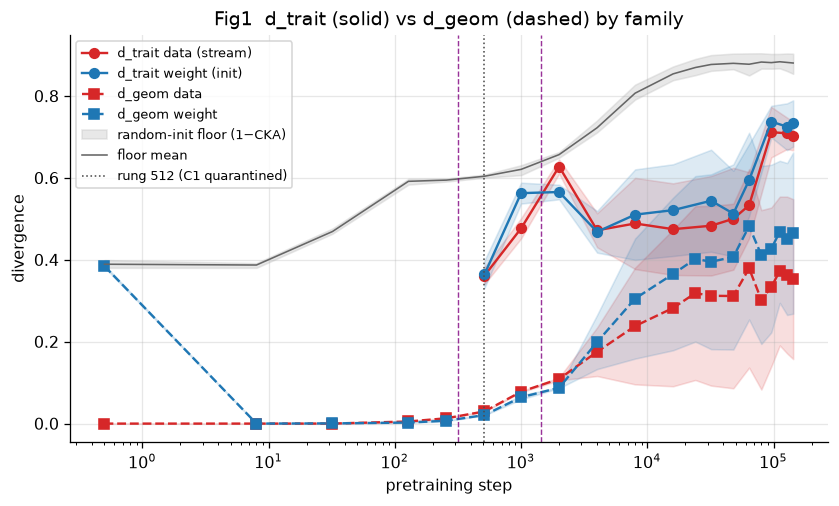

In [5]:
c3 = claim_record("C3")
markers = c3.get("onset_marker_steps") or []
print("C3 onset_marker_steps (live):", markers)

dprim = primary_frame(div)
dprim = dprim[dprim["family"].isin(["data", "weight"])].copy()
scope(dprim, f"d_trait source; n_slots unique={sorted(dprim['n_slots'].unique().tolist())}")
print("n_slots note: 39 = 13 slots × 3 ftseeds if attach_d_trait dropped ftseed from group keys")

p1 = one_convention(
    sim[sim["metric"].astype(str) == str(plan.Metric.MINIBATCH_CKA)],
    "p1 cka",
    CONVENTION,
)
p1 = p1[p1["animal"].isna()].copy()
p1 = maybe_slot(p1)
p1 = with_init_labels(p1)
p1 = attach_family_undirected(p1)
p1 = p1[p1["family"].isin(["data", "weight"])].copy()
p1["d_geom"] = 1.0 - p1["value"].astype(float)
n_slots_geom = p1.groupby(["model_a", "model_b", "step"])["slot"].nunique()
print("P1 CKA n_slots per pair×step:", sorted(n_slots_geom.unique().tolist()), "convention", CONVENTION)
p1_pair = (
    p1.groupby(["family", "step", "model_a", "model_b"], dropna=False)["d_geom"]
    .mean()
    .reset_index()
)
scope(p1_pair, "P1 d_geom pairing-level (slot-mean)")

floor_rows = []
n_diag = 0
try:
    for path, blob in iter_p1_diagnostics(CONVENTION):
        n_diag += 1
        if blob.get("slot_convention") != CONVENTION:
            continue
        for item in blob.get("floor") or []:
            nested = item.get("slot_mean_cka_vs_random_init") or {}
            vals = [
                float(v)
                for init_map in nested.values()
                if isinstance(init_map, dict)
                for v in init_map.values()
            ]
            if not vals:
                continue
            floor_rows.append(
                {
                    "step": int(item["step"]),
                    "mean_cka": float(np.mean(vals)),
                    "lo_cka": float(np.min(vals)),
                    "hi_cka": float(np.max(vals)),
                    "n": len(vals),
                }
            )
except FileNotFoundError as err:
    print("SCOPE gap: parts diagnostics not readable:", err)
print("P1 post_block diagnostic shards loaded:", n_diag, "floor rows:", len(floor_rows))
floor = pd.DataFrame(floor_rows).drop_duplicates("step").sort_values("step")
if not floor.empty:
    floor["d_floor"] = 1.0 - floor["mean_cka"]
    floor["d_floor_lo"] = 1.0 - floor["hi_cka"]
    floor["d_floor_hi"] = 1.0 - floor["lo_cka"]
    floor = add_step_x(floor)
    scope(floor, "Kornblith random-init floor (1 - slot_mean_cka_vs_random_init)")

d_fam = add_step_x(dprim)
g_fam = add_step_x(p1_pair)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
aplots.dose_response(
    ax, d_fam, "x", "d_trait", "family",
    order=["data", "weight"], colors=FAMILY_COLORS,
    labels={"data": "d_trait data (stream)", "weight": "d_trait weight (init)"},
)
aplots.dose_response(
    ax, g_fam, "x", "d_geom", "family",
    order=["data", "weight"], colors=FAMILY_COLORS,
    labels={"data": "d_geom data", "weight": "d_geom weight"},
    marker="s",
)
# Restyle the d_geom lines as dashed (dose_response does not take ls).
for line in ax.get_lines()[-2:]:
    line.set_linestyle("--")
if not floor.empty:
    ax.fill_between(
        floor["x"], floor["d_floor_lo"], floor["d_floor_hi"],
        color="0.75", alpha=0.35, label="random-init floor (1−CKA)",
    )
    ax.plot(floor["x"], floor["d_floor"], color="0.4", lw=1, label="floor mean")
ax.axvline(step_x(512), color="0.3", ls=":", lw=1, label="rung 512 (C1 quarantined)")
for m in markers:
    ax.axvline(float(m), color="purple", ls="--", lw=0.9, alpha=0.8)
ax.set_xscale("log")
ax.set_xlabel("pretraining step")
ax.set_ylabel("divergence")
ax.legend(fontsize=8, loc="best")
ax.set_title("Fig1  d_trait (solid) vs d_geom (dashed) by family")
plt.show()


## 3. Fig2 — Transfer gap

**What this measures.** `subliminal_delta` (raw SL vs matched control) and `y`
(gap vs the SI∩SS anchor) vs log(step) by cell, **test / prob only**. CI from
`dose_response` with pairing-level rows as the sampling unit (already
seed-aggregated). SI∩SS is the raw SL effect; its `y` is 0.


SCOPE: n=276 | animal=1 | set=1 | cell=3 | family=3 | step=12 | pairing_index=23 | Fig2 test/prob pairing-level


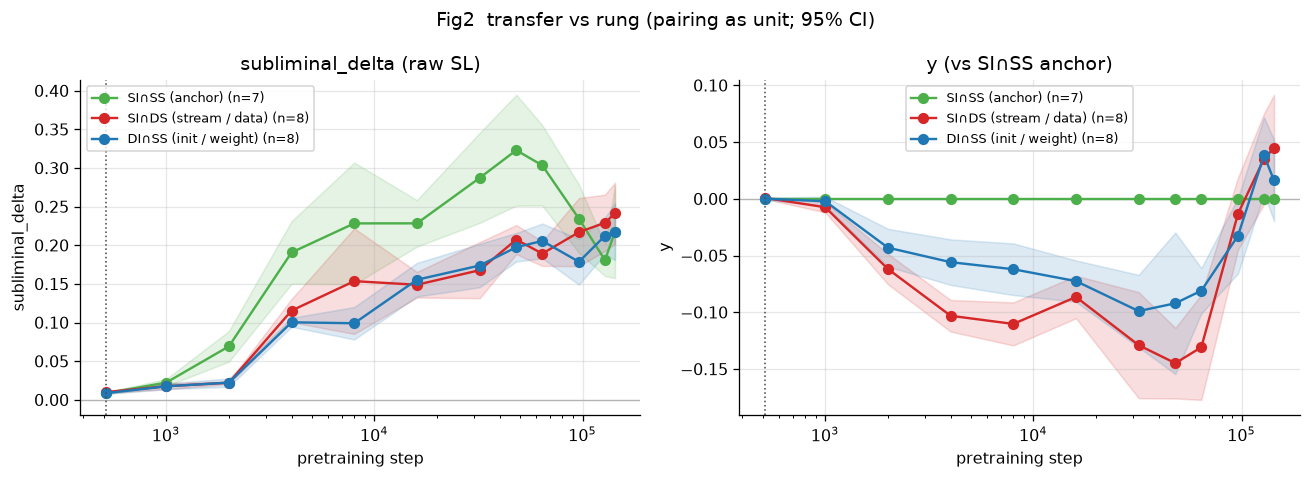

In [6]:
prim = primary_frame(delta)
scope(prim, "Fig2 test/prob pairing-level")
prim_x = add_step_x(prim)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharex=True)
for ax, col, title in (
    (axes[0], "subliminal_delta", "subliminal_delta (raw SL)"),
    (axes[1], "y", "y (vs SI∩SS anchor)"),
):
    aplots.dose_response(
        ax, prim_x, "x", col, "cell",
        order=["SI_SS", "SI_DS", "DI_SS"],
        colors=CELL_COLORS, labels=CELL_LABELS,
        zero_line=True,
        count_fn=lambda s: int(s["pairing_index"].nunique()),
    )
    ax.set_xscale("log")
    ax.axvline(step_x(512), color="0.3", ls=":", lw=1)
    ax.set_title(title)
    ax.legend(fontsize=8)
axes[0].set_xlabel("pretraining step")
axes[1].set_xlabel("pretraining step")
fig.suptitle("Fig2  transfer vs rung (pairing as unit; 95% CI)")
plt.tight_layout()
plt.show()


## 4. Fig3 — Money plot (C1)

**What this measures.** `y ~ d_trait + family + d_trait×family` on the C1 fit
frame (`ladder_delta_agg`: contrast pairings × admitted rungs; counts printed
below). OLS slopes use **`ladder_regression.csv` coefficients**, not a notebook
re-fit. The design includes an intercept that the CSV omits; `β0` is recovered
from the OLS identity on this frame (`ȳ = β0 + β1 d̄ + β2 f̄ + β3 (d·f)̄`).
data (coded 0): `y = β0 + β1 d_trait`. weight (coded 1):
`y = β0 + β2 + (β1+β3) d_trait`. CIs and status are printed from `claims.json`
/ the regression CSV.


C1 status: inconclusive n_obs: 176 n_clusters: 176
equivalence_bound: 0.05
beta1_d_trait (est, lo, hi): [0.25794902099467254, 0.16020916755672246, 0.35568887443262265]
beta2_family: [0.07707406350282542, 0.004717737097667263, 0.14943038990798357]
beta3_interaction: [-0.10850457392179397, -0.23842162509115378, 0.021412477247565842]
beta3_cluster_bootstrap: [-0.10850457392179397, -0.35276778328776265, 0.11049615285423427]
tost_mean_y: {'estimate': 0.020116597631384122, 'ci': [0.004603211209616589, 0.03562998405315165], 'p_value': 0.0029049911954269563, 'equivalent': True, 'n_rungs': 11}
SCOPE: n=176 | animal=1 | family=2 | step=11 | pairing_index=16 | C1 fit frame (ladder_delta_agg)
agg families: {'data': 88, 'weight': 88}
agg steps: [1000, 2000, 4000, 8000, 16000, 32000, 48000, 64000, 96000, 128000, 143000]
OLS from CSV + intercept identity: beta0 -0.20915926067290608 beta1 0.2579490209946725 beta2 0.0770740635028254 beta3 -0.1085045739217939
lstsq intercept vs identity abs diff: 1.3877

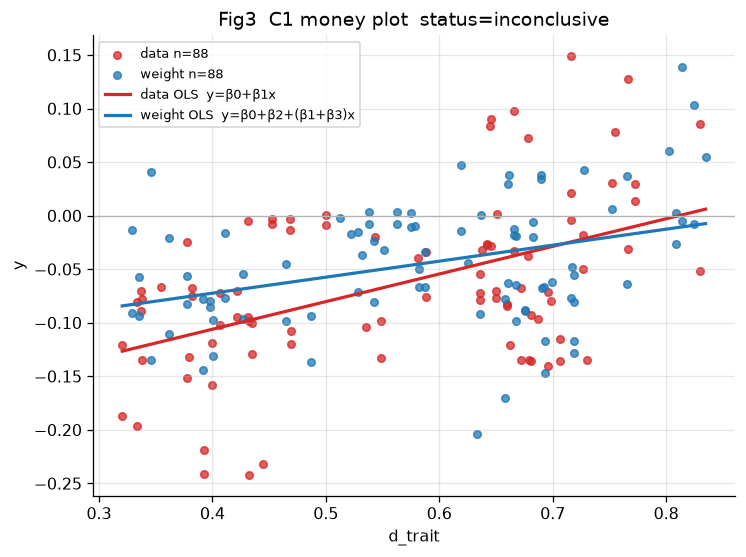

In [7]:
c1 = claim_record("C1")
print("C1 status:", c1.get("status"), "n_obs:", c1.get("n_obs"), "n_clusters:", c1.get("n_clusters"))
print("equivalence_bound:", c1.get("equivalence_bound"))
print("beta1_d_trait (est, lo, hi):", c1.get("beta1_d_trait"))
print("beta2_family:", c1.get("beta2_family"))
print("beta3_interaction:", c1.get("beta3_interaction"))
print("beta3_cluster_bootstrap:", c1.get("beta3_cluster_bootstrap"))
print("tost_mean_y:", c1.get("tost_mean_y"))
scope(agg, "C1 fit frame (ladder_delta_agg)")
print("agg families:", agg["family"].value_counts().to_dict())
print("agg steps:", sorted(int(s) for s in agg["step"].unique()))

c1_reg = reg[reg["claim"] == "C1"].set_index("term")
b1 = float(c1_reg.loc["beta1_d_trait", "estimate"])
b2 = float(c1_reg.loc["beta2_family", "estimate"])
b3 = float(c1_reg.loc["beta3_interaction", "estimate"])
fam = (agg["family"].astype(str) == "weight").to_numpy(dtype=float)
d = agg["d_trait"].to_numpy(dtype=float)
y = agg["y"].to_numpy(dtype=float)
b0 = float(y.mean() - b1 * d.mean() - b2 * fam.mean() - b3 * (d * fam).mean())
design = np.column_stack([np.ones_like(y), d, fam, d * fam])
b_lstsq = np.linalg.lstsq(design, y, rcond=None)[0]
print("OLS from CSV + intercept identity: beta0", b0, "beta1", b1, "beta2", b2, "beta3", b3)
print("lstsq intercept vs identity abs diff:", abs(float(b_lstsq[0]) - b0))
print("agg n_obs", len(agg), "pairings", agg["pairing_index"].nunique(), "rungs", agg["step"].nunique())
print("512 in agg?:", 512 in set(int(s) for s in agg["step"]))
print("SI_SS in agg family?:", "SI_SS" in set(agg["family"].astype(str)))

fig, ax = plt.subplots(figsize=(7.2, 5.2))
for fam_name, sub in agg.groupby("family"):
    ax.scatter(
        sub["d_trait"], sub["y"], s=22, alpha=0.75,
        color=FAMILY_COLORS.get(str(fam_name), "0.4"),
        label=f"{fam_name} n={len(sub)}",
    )
xs = np.linspace(float(agg["d_trait"].min()), float(agg["d_trait"].max()), 80)
ax.plot(
    xs, b0 + b1 * xs, color=FAMILY_COLORS["data"], lw=2,
    label="data OLS  y=β0+β1x",
)
ax.plot(
    xs, b0 + b2 + (b1 + b3) * xs, color=FAMILY_COLORS["weight"], lw=2,
    label="weight OLS  y=β0+β2+(β1+β3)x",
)
ax.axhline(0.0, color="0.7", lw=0.8)
ax.set_xlabel("d_trait")
ax.set_ylabel("y")
ax.legend(fontsize=8)
ax.set_title(f"Fig3  C1 money plot  status={c1.get('status')}")
plt.show()


## 5. Fig4 — Emergence (C3)

**What this measures.** Mean SI∩SS `subliminal_delta` vs the prereg threshold
vs step (`ladder_emergence`). C3 includes quarantine rungs; C1 does not.
Literature vlines from claims `onset_marker_steps`. Status and onset step are
printed live.


C3 status: onset onset_step: 512
includes_quarantine_rungs: True
sd_multiple: 2.0 n_rungs_scored: 12
onset_markers fractions: [0.0022, 0.01] steps: [315, 1430]
SCOPE: n=12 | animal=1 | step=12 | ladder_emergence
animal   step  mean_delta  replicate_sd  threshold  clears  n
   cat    512    0.008587      0.001537   0.003074    True  7
   cat   1000    0.022361      0.006215   0.012430    True  7
   cat   2000    0.069237      0.026728   0.053457    True  7
   cat   4000    0.190736      0.054648   0.109296    True  7
   cat   8000    0.228377      0.106207   0.212413    True  7
   cat  16000    0.228404      0.040596   0.081192    True  7
   cat  32000    0.287157      0.078546   0.157093    True  7
   cat  48000    0.323052      0.096779   0.193558    True  7
   cat  64000    0.303448      0.070155   0.140309    True  7
   cat  96000    0.234382      0.059482   0.118964    True  7
   cat 128000    0.180821      0.027707   0.055415    True  7
   cat 143000    0.217487      0.080810   0.

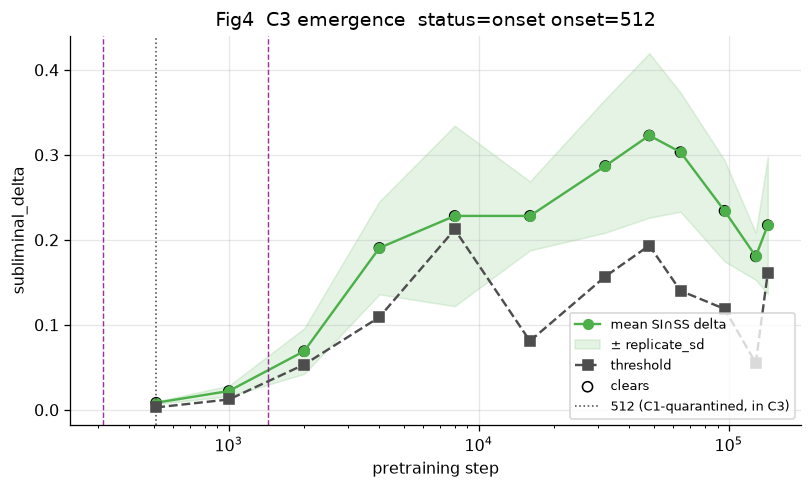

Note: step 512 is C1-quarantined (advisory teachers) but C3 includes it by prereg.


In [8]:
c3 = claim_record("C3")
print("C3 status:", c3.get("status"), "onset_step:", c3.get("onset_step"))
print("includes_quarantine_rungs:", c3.get("includes_quarantine_rungs"))
print("sd_multiple:", c3.get("sd_multiple"), "n_rungs_scored:", c3.get("n_rungs_scored"))
print("onset_markers fractions:", c3.get("onset_markers"), "steps:", c3.get("onset_marker_steps"))
scope(c3_tab, "ladder_emergence")
print(c3_tab.to_string(index=False))
print("all clears:", bool(c3_tab["clears"].all()), "n per rung:", c3_tab["n"].unique().tolist())

em = add_step_x(c3_tab)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.plot(em["x"], em["mean_delta"], marker="o", color=CELL_COLORS["SI_SS"], label="mean SI∩SS delta")
ax.fill_between(
    em["x"],
    em["mean_delta"] - em["replicate_sd"],
    em["mean_delta"] + em["replicate_sd"],
    color=CELL_COLORS["SI_SS"], alpha=0.15, label="± replicate_sd",
)
ax.plot(em["x"], em["threshold"], marker="s", color="0.3", ls="--", label="threshold")
cleared = em[em["clears"].astype(bool)]
ax.scatter(cleared["x"], cleared["mean_delta"], s=40, facecolors="none", edgecolors="k", label="clears")
ax.axvline(step_x(512), color="0.3", ls=":", lw=1, label="512 (C1-quarantined, in C3)")
for m in c3.get("onset_marker_steps") or []:
    ax.axvline(float(m), color="purple", ls="--", lw=0.9, alpha=0.8)
ax.set_xscale("log")
ax.set_xlabel("pretraining step")
ax.set_ylabel("subliminal_delta")
ax.legend(fontsize=8)
ax.set_title(f"Fig4  C3 emergence  status={c3.get('status')} onset={c3.get('onset_step')}")
plt.show()
print("Note: step 512 is C1-quarantined (advisory teachers) but C3 includes it by prereg.")


## 6. Fig5 — Basis breakdown (C4)

**What this measures.** Rotation-invariant vs per-coordinate dissimilarity vs
step (`ladder_basis_breakdown`). C4's per-coordinate metric on disk is `ssa`
(normalised `/90`); `shared_basis_subspace_cka` is **absent**. Gap is plotted
as stored. Status printed live. `n_pairs` in the CSV is a **row count**
(not unique pairings). The pipeline table means SSA over **both** slot
conventions vs trait on `hidden_states` only — this notebook plots that CSV
and does not re-derive C4.


C4 status: no_breakdown breakdown_step: None
per_coordinate_metric: ssa
normalisation: ssa degrees / 90
gap_median / mad / threshold: -0.15699950606689617 0.04149342078467838 -0.03251924371286102
SCOPE: n=12 | step=12 | ladder_basis_breakdown
  step  rotation_invariant  per_coordinate       gap  n_pairs
   512            0.361170        0.188351 -0.172819      832
  1000            0.476965        0.284590 -0.192375      832
  2000            0.627789        0.312184 -0.315606      832
  4000            0.472122        0.330942 -0.141180      832
  8000            0.488737        0.364223 -0.124514      832
 16000            0.474834        0.398781 -0.076053      832
 32000            0.483248        0.432702 -0.050546      832
 48000            0.500269        0.455650 -0.044619      832
 64000            0.533165        0.468484 -0.064682      832
 96000            0.711765        0.507153 -0.204611      832
128000            0.708940        0.523784 -0.185156      832
143000       

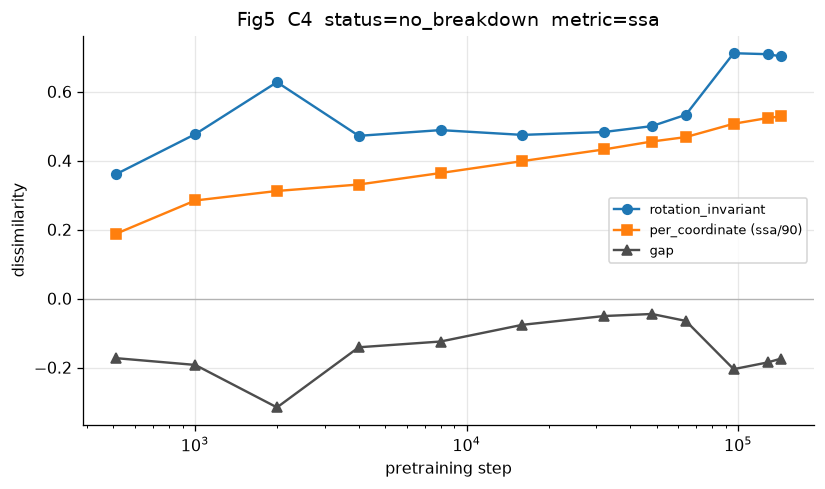

In [9]:
c4 = claim_record("C4")
print("C4 status:", c4.get("status"), "breakdown_step:", c4.get("breakdown_step"))
print("per_coordinate_metric:", c4.get("per_coordinate_metric"))
print("normalisation:", c4.get("normalisation"))
print("gap_median / mad / threshold:", c4.get("gap_median"), c4.get("gap_mad"), c4.get("gap_threshold"))
scope(c4_tab, "ladder_basis_breakdown")
print(c4_tab.to_string(index=False))
print("gap sign (all negative?):", bool((c4_tab["gap"] < 0).all()))

bd = add_step_x(c4_tab)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.plot(bd["x"], bd["rotation_invariant"], marker="o", label="rotation_invariant")
ax.plot(bd["x"], bd["per_coordinate"], marker="s", label="per_coordinate (ssa/90)")
ax.plot(bd["x"], bd["gap"], marker="^", color="0.3", label="gap")
ax.axhline(0.0, color="0.7", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("pretraining step")
ax.set_ylabel("dissimilarity")
ax.legend(fontsize=8)
ax.set_title(f"Fig5  C4  status={c4.get('status')}  metric={c4.get('per_coordinate_metric')}")
plt.show()


## 7. Fig6 — Capability confound (C5)

**What this measures.** Per-rung Spearman(`y`, `perplexity_ratio`) from claims
C5; `perplexity_ratio` vs step by family (test); teacher `p_target` from the
admission report; P1b `acc` vs log(step) faceted by task. **Pile corpus PPL is
absent** from the capability CSV. Threshold `C5_SPEARMAN_ABS_QUARANTINE`.


C5 status: quarantine_confound threshold: 0.5
max_abs_spearman: {'step': 16000, 'rho': 0.6684024428237836}


,step,spearman
0,512,-0.271570
1,1000,-0.291612
2,2000,0.426896
3,4000,0.552159
4,8000,0.580217
5,16000,0.668402
6,32000,0.482011
7,48000,-0.004008
8,64000,0.025053
9,96000,-0.107225


SCOPE: n=192 | animal=1 | set=1 | cell=2 | family=2 | step=12 | slot_convention=1 | pairing_index=16 | perplexity_ratio vs step
capability tasks (no Pile): ['arc_easy', 'lambada_openai', 'sciq']
capability metrics: ['acc', 'acc_norm', 'perplexity', 'sample_len']


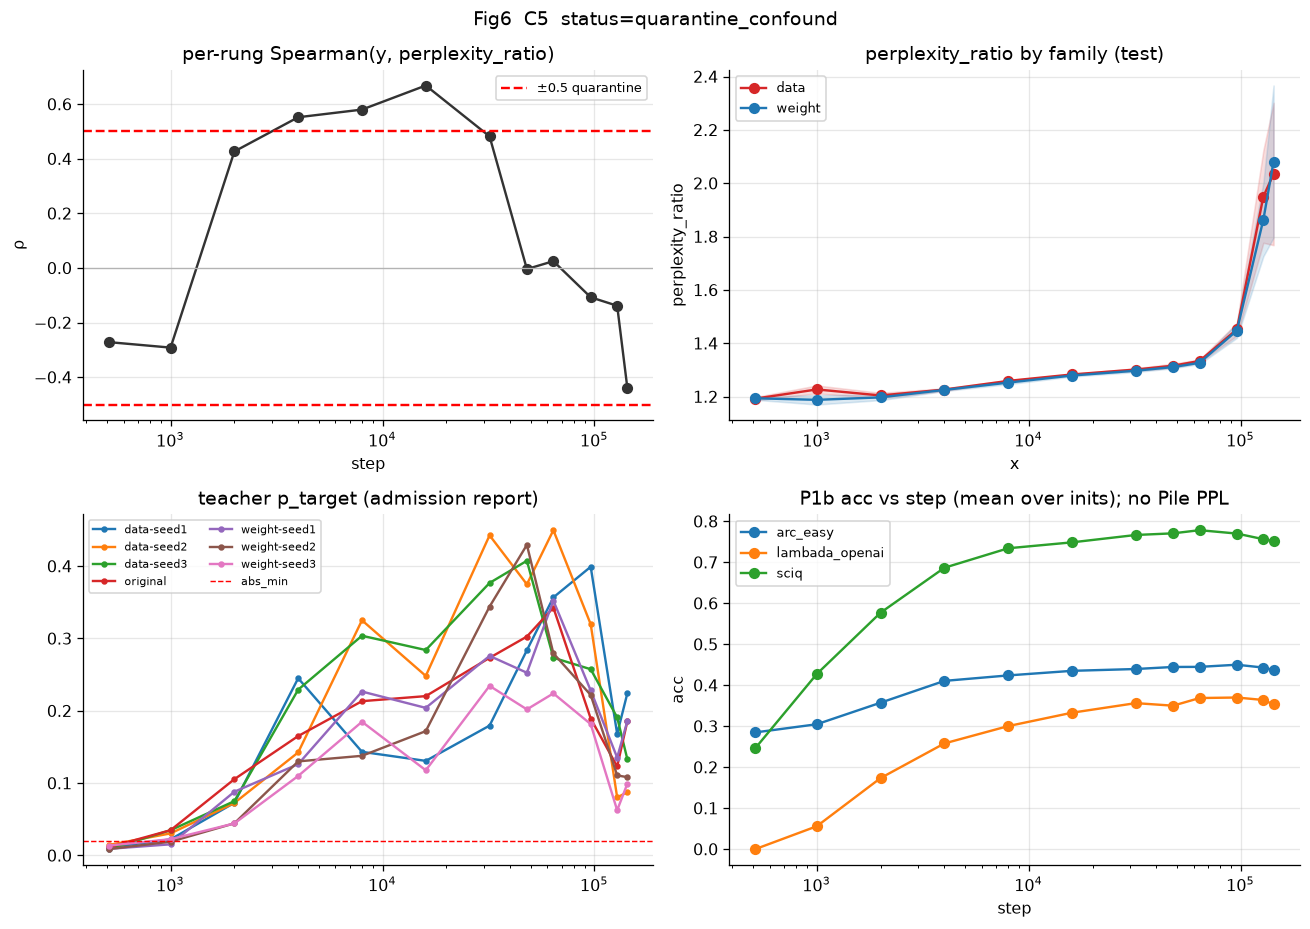

In [10]:
c5 = claim_record("C5")
print("C5 status:", c5.get("status"), "threshold:", c5.get("threshold"))
print("max_abs_spearman:", c5.get("max_abs_spearman"))
rho = c5.get("per_rung_spearman") or {}
rho_df = pd.DataFrame(
    [{"step": int(k), "spearman": v} for k, v in rho.items()]
).sort_values("step")
display(rho_df)
thr = float(c5.get("threshold", plan.C5_SPEARMAN_ABS_QUARANTINE))

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))
ax = axes[0, 0]
ax.plot(rho_df["step"].map(step_x), rho_df["spearman"], marker="o", color="0.2")
ax.axhline(thr, color="red", ls="--", label=f"±{thr:g} quarantine")
ax.axhline(-thr, color="red", ls="--")
ax.axhline(0.0, color="0.7", lw=0.8)
ax.set_xscale("log")
ax.set_title("per-rung Spearman(y, perplexity_ratio)")
ax.set_xlabel("step")
ax.set_ylabel("ρ")
ax.legend(fontsize=8)

prim = primary_frame(div)
ppl = prim[prim["family"].isin(["data", "weight"])].copy()
scope(ppl, "perplexity_ratio vs step")
ppl = add_step_x(ppl)
aplots.dose_response(
    axes[0, 1], ppl, "x", "perplexity_ratio", "family",
    order=["data", "weight"], colors=FAMILY_COLORS, zero_line=False,
)
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("perplexity_ratio by family (test)")
axes[0, 1].legend(fontsize=8)

adm = pd.DataFrame(ADMISSION["cells"])
adm = add_step_x(adm, src="rung")
for init, sub in adm.groupby("init"):
    axes[1, 0].plot(sub["x"], sub["teacher_p_target"], marker="o", ms=3, label=init)
axes[1, 0].axhline(plan.ADMISSION_ABS_MIN, color="red", ls="--", lw=0.9, label="abs_min")
axes[1, 0].set_xscale("log")
axes[1, 0].set_title("teacher p_target (admission report)")
axes[1, 0].legend(fontsize=7, ncol=2)

acc = cap[cap["metric"].astype(str) == "acc"].copy()
print("capability tasks (no Pile):", sorted(cap["task"].unique().tolist()))
print("capability metrics:", sorted(cap["metric"].unique().tolist()))
acc = add_step_x(acc)
for task, sub in acc.groupby("task"):
    g = sub.groupby("x")["value"].mean().sort_index()
    axes[1, 1].plot(g.index, g.values, marker="o", label=task)
axes[1, 1].set_xscale("log")
axes[1, 1].set_title("P1b acc vs step (mean over inits); no Pile PPL")
axes[1, 1].set_xlabel("step")
axes[1, 1].set_ylabel("acc")
axes[1, 1].legend(fontsize=8)
fig.suptitle(f"Fig6  C5  status={c5.get('status')}")
plt.tight_layout()
plt.show()


## 8. Fig7 — Variance components

**What this measures.** Stacked fractions of `subliminal_delta` SS at the two
crossed-anchor rungs (`ladder_variance_components`). This run's numbers come
from the CSV. Stage B cat split (pairing 67.5% / ftseed 10.5% / gseed 22.1%)
is the **plan's published Stage B context**, not this run.


SCOPE: n=8 | animal=1 | step=2 | variance components
animal  step         response   factor  sum_of_squares  fraction  n_obs          entry_order
   cat  2000 subliminal_delta  pairing        0.106373  0.905411    159 pairing|ftseed|gseed
   cat  2000 subliminal_delta   ftseed        0.000157  0.001336    159 pairing|ftseed|gseed
   cat  2000 subliminal_delta    gseed        0.001534  0.013057    159 pairing|ftseed|gseed
   cat  2000 subliminal_delta residual        0.009422  0.080196    159 pairing|ftseed|gseed
   cat 64000 subliminal_delta  pairing        0.718893  0.870400    159 pairing|ftseed|gseed
   cat 64000 subliminal_delta   ftseed        0.006438  0.007795    159 pairing|ftseed|gseed
   cat 64000 subliminal_delta    gseed        0.009292  0.011250    159 pairing|ftseed|gseed
   cat 64000 subliminal_delta residual        0.091312  0.110556    159 pairing|ftseed|gseed
n_obs unique: [159]


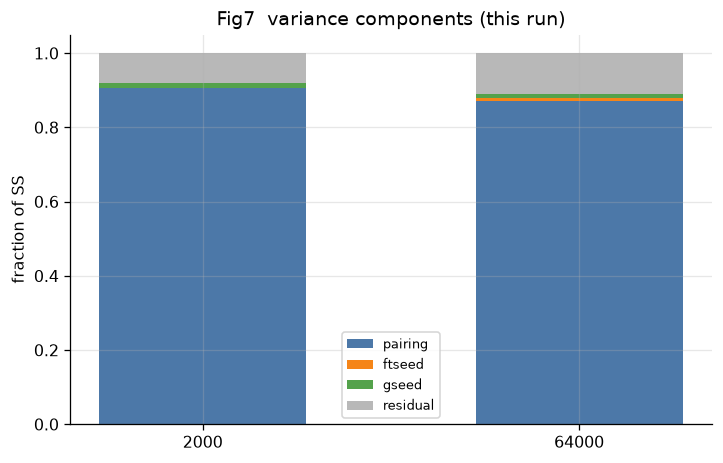

Stage B published cat split (plan literature context, not this CSV): pairing 67.5% / ftseed 10.5% / gseed 22.1%


In [11]:
scope(var, "variance components")
print(var.to_string(index=False))
print("n_obs unique:", var["n_obs"].unique().tolist())

factor_order = ["pairing", "ftseed", "gseed", "residual"]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
x_pos = np.arange(2)
width = 0.55
bottom = np.zeros(2)
rungs = [2000, 64000]
colors_f = {
    "pairing": "#4c78a8",
    "ftseed": "#f58518",
    "gseed": "#54a24b",
    "residual": "#b8b8b8",
}
for fac in factor_order:
    vals = []
    for rung in rungs:
        row = var[(var["step"] == rung) & (var["factor"] == fac)]
        vals.append(float(row["fraction"].iloc[0]) if len(row) else np.nan)
    ax.bar(x_pos, vals, width, bottom=bottom, color=colors_f[fac], label=fac)
    bottom = bottom + np.nan_to_num(np.asarray(vals, dtype=float), nan=0.0)
ax.set_xticks(x_pos)
ax.set_xticklabels([str(r) for r in rungs])
ax.set_ylabel("fraction of SS")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8)
ax.set_title("Fig7  variance components (this run)")
plt.show()
print(
    "Stage B published cat split (plan literature context, not this CSV): "
    "pairing 67.5% / ftseed 10.5% / gseed 22.1%"
)


## 9. Fig8 — Stage B concordance (C6)

**What this measures.** Pairing-for-pairing scatter of ladder top-rung mean vs
Stage B mean from claims C6 `per_pairing` (23 points). Colour by cell via
`cell_of(student, teacher)`. `n_shared`, Spearman, `n_ci_disjoint` are printed
from claims — not hardcoded here.


C6 status: concordant top_rung: 143000
n_shared: 23 n_comparable: 23
n_ci_disjoint: 0 spearman: 0.9239130434782609
stage_b_run_set_id: 20260727_slbreadth_160m
SCOPE: n=23 | cell=3 | C6 per_pairing
{'SI_DS': 8, 'DI_SS': 8, 'SI_SS': 7}


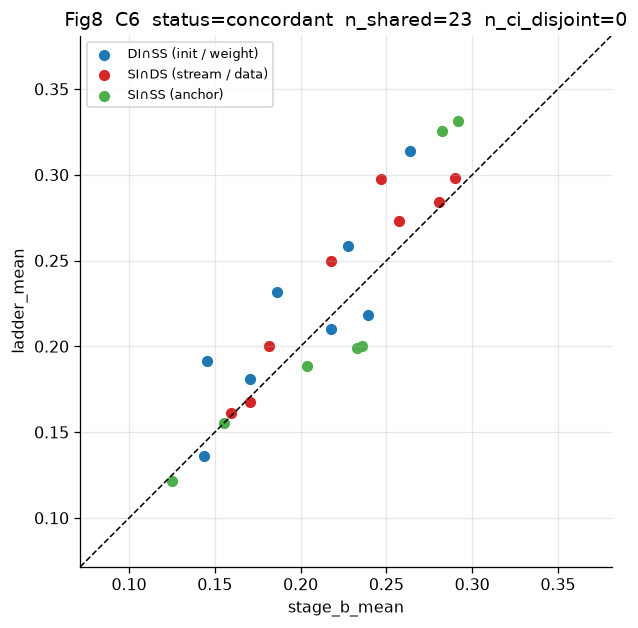

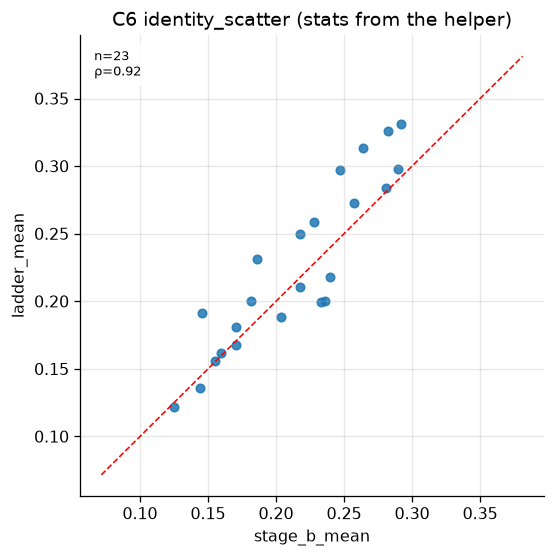

In [12]:
c6 = claim_record("C6")
print("C6 status:", c6.get("status"), "top_rung:", c6.get("top_rung"))
print("n_shared:", c6.get("n_shared"), "n_comparable:", c6.get("n_comparable"))
print("n_ci_disjoint:", c6.get("n_ci_disjoint"), "spearman:", c6.get("spearman"))
print("stage_b_run_set_id:", c6.get("stage_b_run_set_id"))
pp = pd.DataFrame(c6.get("per_pairing") or [])
pp["cell"] = [str(cell_of(s, t)) for s, t in zip(pp["student"], pp["teacher"], strict=True)]
scope(pp, "C6 per_pairing")
print(pp["cell"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(6.4, 6.0))
lo = float(min(pp["ladder_mean"].min(), pp["stage_b_mean"].min())) - 0.05
hi = float(max(pp["ladder_mean"].max(), pp["stage_b_mean"].max())) + 0.05
for cell, sub in pp.groupby("cell"):
    ax.scatter(
        sub["stage_b_mean"], sub["ladder_mean"], s=36,
        color=CELL_COLORS.get(cell, "0.4"), label=CELL_LABELS.get(cell, cell),
    )
ax.plot([lo, hi], [lo, hi], "k--", lw=1)
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_xlabel("stage_b_mean")
ax.set_ylabel("ladder_mean")
ax.legend(fontsize=8)
ax.set_aspect("equal", adjustable="box")
ax.set_title(
    f"Fig8  C6  status={c6.get('status')}  n_shared={c6.get('n_shared')}  "
    f"n_ci_disjoint={c6.get('n_ci_disjoint')}"
)
plt.show()
# identity_scatter on the pooled frame (stats in title); colours above are the claim figure.
fig, ax = plt.subplots(figsize=(5.2, 5.2))
aplots.identity_scatter(
    ax, pp, "stage_b_mean", "ladder_mean",
    s=28, alpha=0.85, stat="spearman", diag_lim=(lo, hi), textbox=True,
)
ax.set_title("C6 identity_scatter (stats from the helper)")
plt.show()


## 10. Fig9 — Prompt-set robustness

**What this measures.** Three views, all four sets, **not extra C1 claims**
except `test`. (1) `y` vs log(step) by family — does the transfer-gap trend
leave `test`? (2) SI∩SS `subliminal_delta` vs log(step) — raw SL, including
whether `storytelling` still shows it and whether `off_topic` stays near the
false-positive floor. (3) `y` vs `d_trait` on admitted rungs — the C1 scatter
refit visually per set (plan fig 9). Storytelling is `sample` on disk; the
others `prob`. Do not pool sets into C1.


SCOPE: n=192 | animal=1 | set=1 | cell=2 | family=2 | step=12 | pairing_index=16 | y vs step set=test scoring=['prob']
SCOPE: n=192 | animal=1 | set=1 | cell=2 | family=2 | step=12 | pairing_index=16 | y vs step set=favorite scoring=['prob']
SCOPE: n=192 | animal=1 | set=1 | cell=2 | family=2 | step=12 | pairing_index=16 | y vs step set=storytelling scoring=['sample']
SCOPE: n=192 | animal=1 | set=1 | cell=2 | family=2 | step=12 | pairing_index=16 | y vs step set=off_topic scoring=['prob']


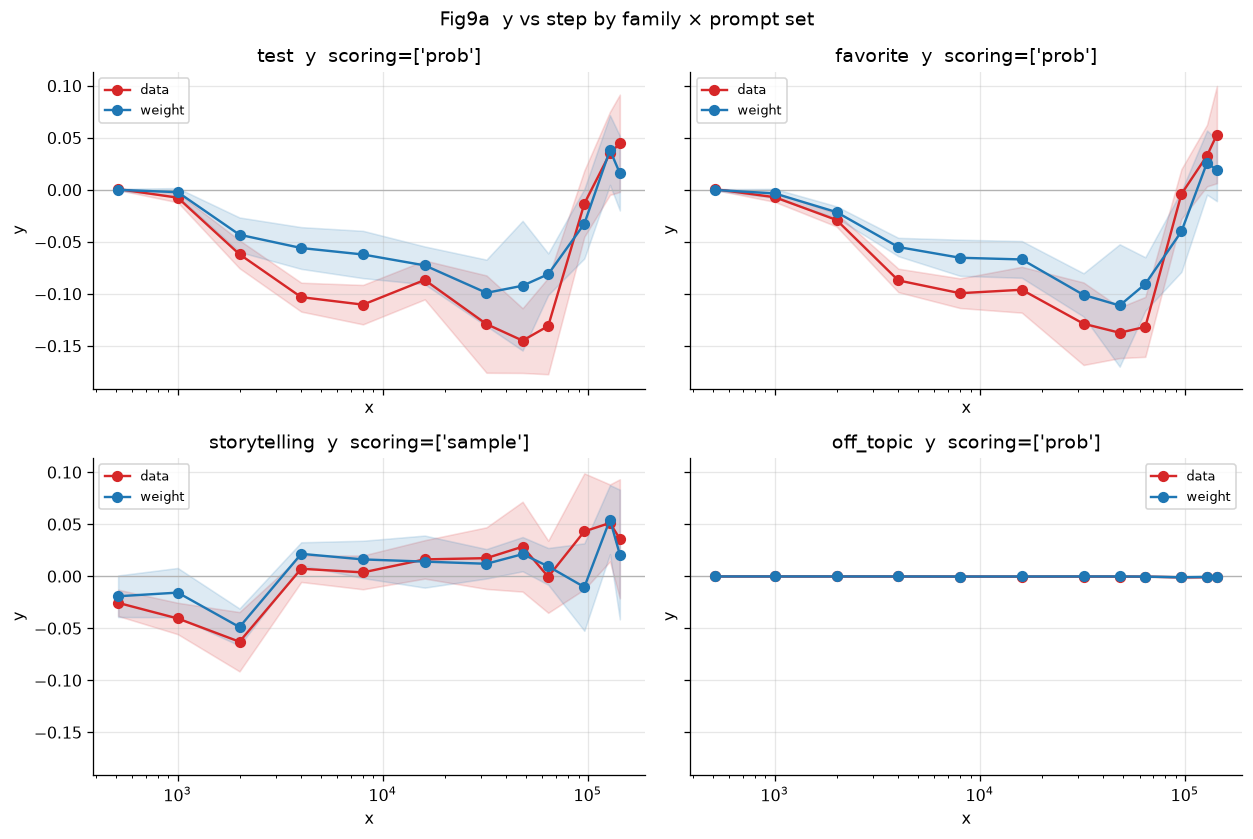

SCOPE: n=84 | animal=1 | set=1 | cell=1 | family=1 | step=12 | pairing_index=7 | SI_SS delta set=test
SCOPE: n=84 | animal=1 | set=1 | cell=1 | family=1 | step=12 | pairing_index=7 | SI_SS delta set=favorite
SCOPE: n=84 | animal=1 | set=1 | cell=1 | family=1 | step=12 | pairing_index=7 | SI_SS delta set=storytelling
SCOPE: n=84 | animal=1 | set=1 | cell=1 | family=1 | step=12 | pairing_index=7 | SI_SS delta set=off_topic


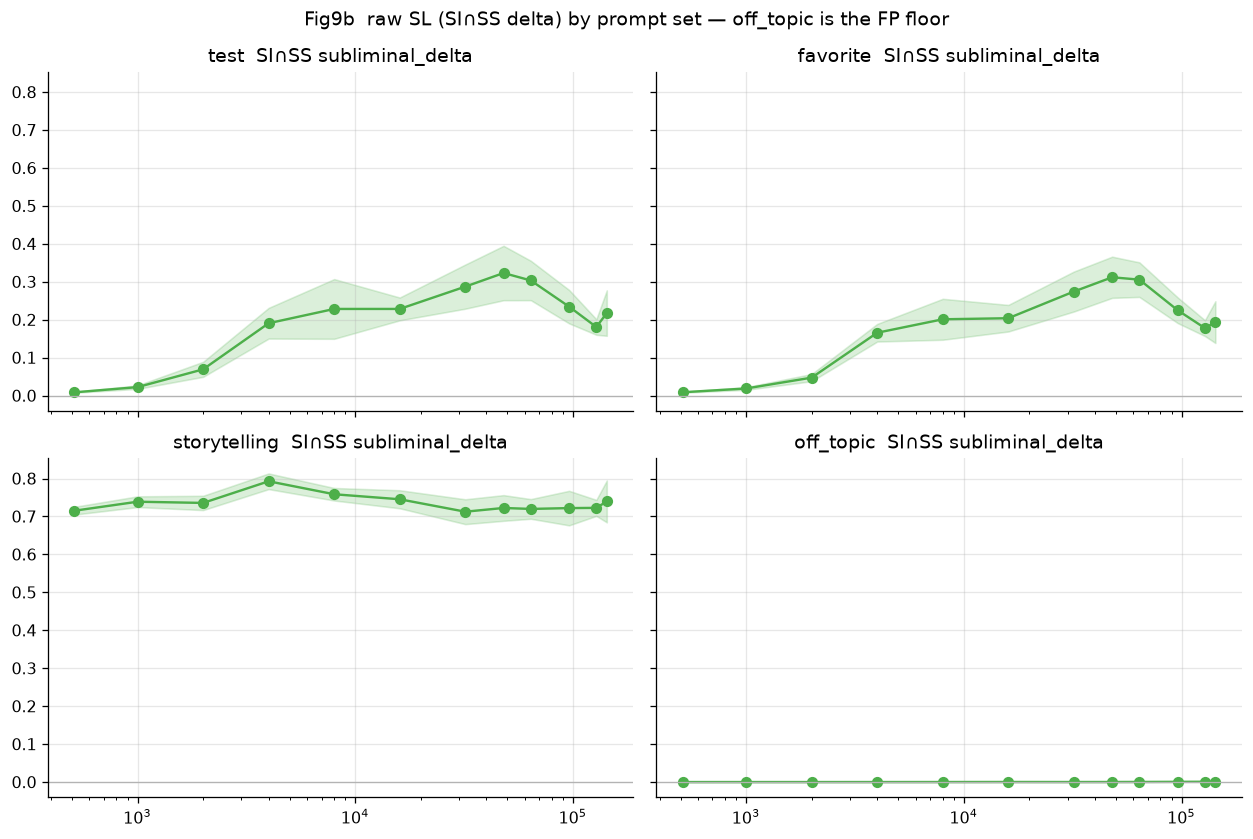

SCOPE: n=176 | animal=1 | set=1 | cell=2 | family=2 | step=11 | slot_convention=1 | pairing_index=16 | C1-style scatter set=test admitted rungs
SCOPE: n=176 | animal=1 | set=1 | cell=2 | family=2 | step=11 | slot_convention=1 | pairing_index=16 | C1-style scatter set=favorite admitted rungs
SCOPE: n=176 | animal=1 | set=1 | cell=2 | family=2 | step=11 | slot_convention=1 | pairing_index=16 | C1-style scatter set=storytelling admitted rungs
SCOPE: n=176 | animal=1 | set=1 | cell=2 | family=2 | step=11 | slot_convention=1 | pairing_index=16 | C1-style scatter set=off_topic admitted rungs


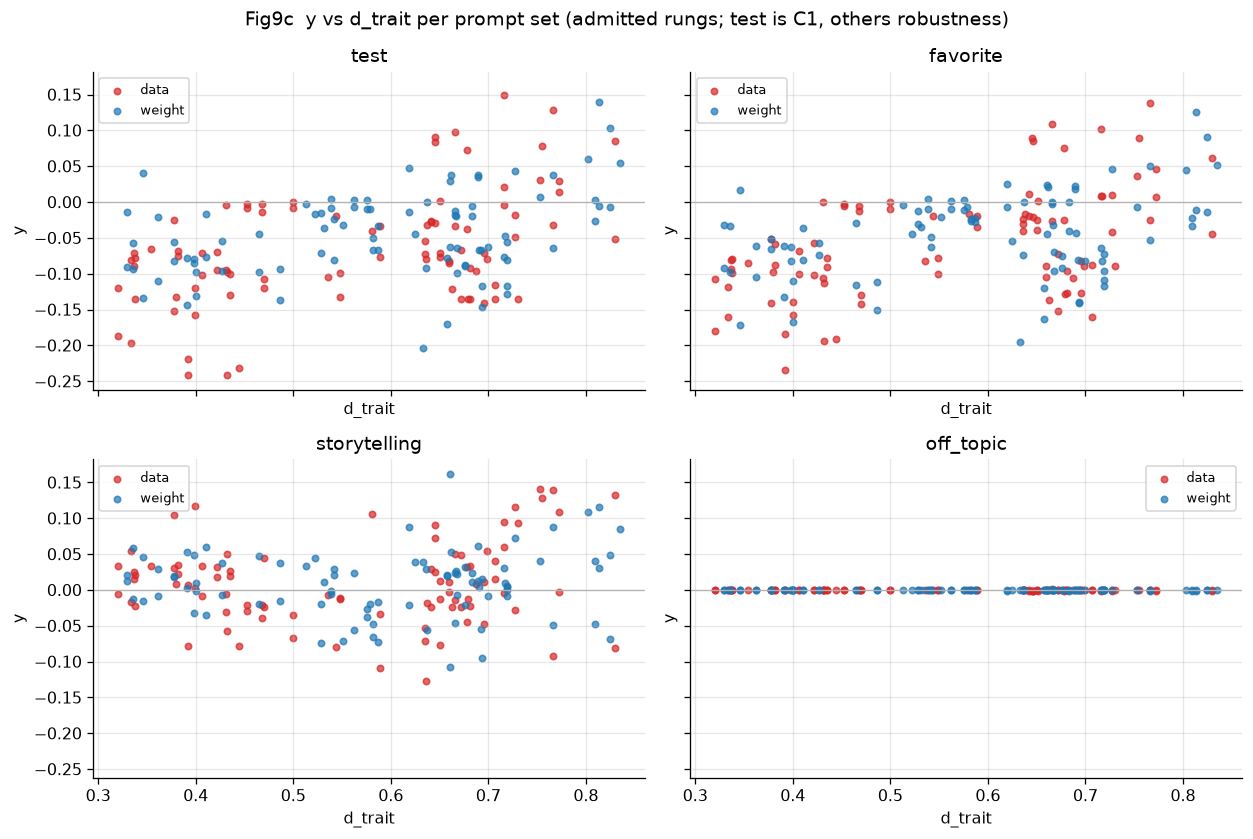

In [13]:
sets = list(plan.EVAL_PROMPT_SETS)
admitted = {int(s) for s in CLAIMS["admitted_rungs"]}

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.4), sharex=True, sharey=True)
for ax, pset in zip(axes.ravel(), sets, strict=True):
    sub = delta[delta["set"].astype(str) == pset].copy()
    sub = sub[sub["family"].isin(["data", "weight"])]
    scoring = sub["scoring"].unique().tolist() if "scoring" in sub.columns else []
    scope(sub, f"y vs step set={pset} scoring={scoring}")
    sub = add_step_x(sub)
    aplots.dose_response(
        ax, sub, "x", "y", "family",
        order=["data", "weight"], colors=FAMILY_COLORS, zero_line=True,
    )
    ax.set_xscale("log")
    ax.set_title(f"{pset}  y  scoring={scoring}")
    ax.legend(fontsize=8)
fig.suptitle("Fig9a  y vs step by family × prompt set")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.4), sharex=True, sharey=True)
for ax, pset in zip(axes.ravel(), sets, strict=True):
    sub = delta[(delta["set"].astype(str) == pset) & (delta["cell"] == "SI_SS")].copy()
    scope(sub, f"SI_SS delta set={pset}")
    sub = add_step_x(sub)
    g = sub.groupby("x")["subliminal_delta"].agg(["mean", "std", "count"]).sort_index()
    ax.plot(g.index, g["mean"], color=CELL_COLORS["SI_SS"], marker="o")
    se = g["std"] / np.sqrt(g["count"].clip(lower=1))
    ax.fill_between(g.index, g["mean"] - 1.96 * se, g["mean"] + 1.96 * se,
                    color=CELL_COLORS["SI_SS"], alpha=0.2)
    ax.axhline(0.0, color="0.7", lw=0.8)
    ax.set_xscale("log")
    ax.set_title(f"{pset}  SI∩SS subliminal_delta")
fig.suptitle("Fig9b  raw SL (SI∩SS delta) by prompt set — off_topic is the FP floor")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.4), sharex=True, sharey=True)
for ax, pset in zip(axes.ravel(), sets, strict=True):
    sub = div[div["set"].astype(str) == pset].copy()
    sub = sub[sub["family"].isin(["data", "weight"])]
    sub = sub[sub["step"].astype(int).isin(admitted)]
    scope(sub, f"C1-style scatter set={pset} admitted rungs")
    for fam, g in sub.groupby("family"):
        ax.scatter(
            g["d_trait"], g["y"], s=16, alpha=0.7,
            color=FAMILY_COLORS.get(str(fam), "0.4"), label=str(fam),
        )
    ax.axhline(0.0, color="0.7", lw=0.8)
    ax.set_title(pset)
    ax.legend(fontsize=8)
    ax.set_xlabel("d_trait")
    ax.set_ylabel("y")
fig.suptitle("Fig9c  y vs d_trait per prompt set (admitted rungs; test is C1, others robustness)")
plt.tight_layout()
plt.show()


## 11. Fig10 — Self-drift (C7)

**What this measures.** Consecutive-rung `minibatch_cka` and `ssa` for each of
the 7 inits (mean over slots, **`post_block` only** — never average conventions).
x = midpoint step. Dashed CKA: mean over data+weight P1 pairs at the later
rung. Dashed SSA: **data family only** (shared init) — SSA is not defined on
broken-basis (weight / DI∩SS) pairs. PolyPythias shape (literature): SSA
rises ~10³, plateaus ~10⁴, falls toward ~20°.


C7 status: reported n_rows: 6916 n_consecutive_pairs: 19
per_metric: {'minibatch_cka': {'self_drift_mean': 0.8754539686754782, 'cross_init_mean': 0.7694003276693618, 'n_drift_rows': 3458}, 'ssa': {'self_drift_mean': 23.806909626518657, 'cross_init_mean': 28.223438606841732, 'n_drift_rows': 3458}}
SCOPE: n=3458 | slot=13 | slot_convention=1 | metric=2 | self_drift post_block
basis_validity: ['basis_lineage']
metrics: ['minibatch_cka', 'ssa']


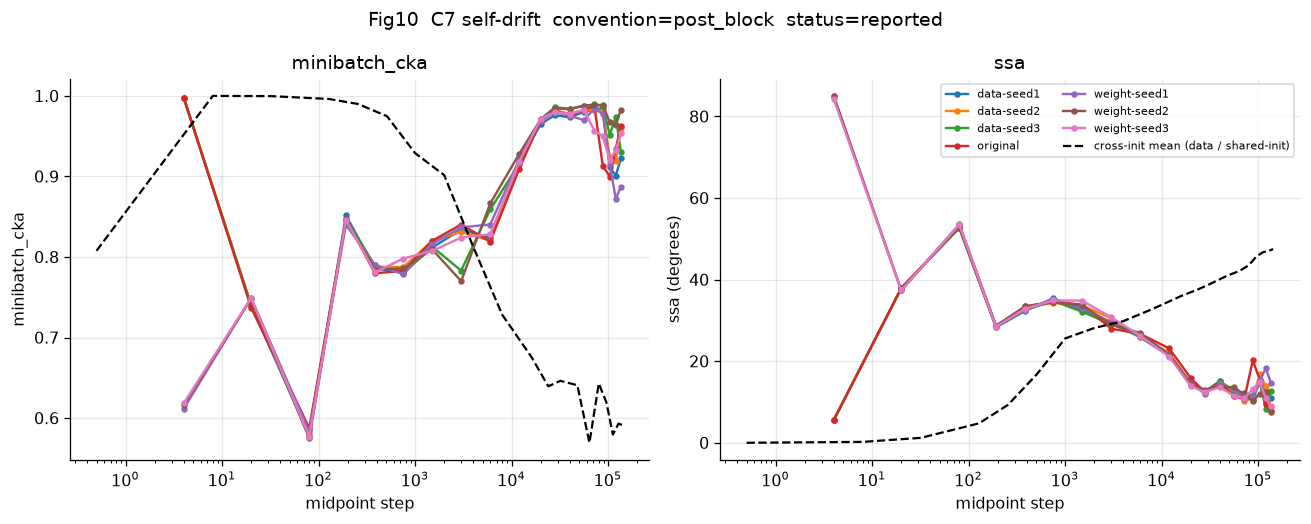

In [14]:
c7 = claim_record("C7")
print("C7 status:", c7.get("status"), "n_rows:", c7.get("n_rows"), "n_consecutive_pairs:", c7.get("n_consecutive_pairs"))
print("per_metric:", c7.get("per_metric"))
dconv = one_convention(drift, "self_drift", CONVENTION)
dconv = maybe_slot(dconv)
scope(dconv, f"self_drift {CONVENTION}")
print("basis_validity:", dconv["basis_validity"].unique().tolist())
print("metrics:", dconv["metric"].unique().tolist())

def _init_from_model(model: str) -> str:
    return canonical_label(str(model))

dconv["init"] = [_init_from_model(m) for m in dconv["model"]]
dconv["mid"] = 0.5 * (dconv["step_a"].astype(float) + dconv["step_b"].astype(float))
slot_mean = (
    dconv.groupby(["init", "mid", "step_b", "metric"], dropna=False)["value"]
    .mean()
    .reset_index()
)

p1 = one_convention(
    sim[sim["metric"].isin([str(plan.Metric.MINIBATCH_CKA), str(plan.Metric.SSA)])],
    "p1 cross",
    CONVENTION,
)
p1 = p1[p1["animal"].isna()].copy()
p1 = maybe_slot(p1)
p1 = with_init_labels(p1)
p1 = attach_family_undirected(p1)
p1 = p1[p1["family"].isin(["data", "weight"])]
# CKA is defined on both families; SSA only on shared-init (data / SI∩DS).
cross_by_metric = {
    str(plan.Metric.MINIBATCH_CKA): (
        p1[p1["metric"] == str(plan.Metric.MINIBATCH_CKA)]
        .groupby("step", dropna=False)["value"].mean().reset_index()
    ),
    str(plan.Metric.SSA): (
        p1[(p1["metric"] == str(plan.Metric.SSA)) & (p1["family"] == "data")]
        .groupby("step", dropna=False)["value"].mean().reset_index()
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True)
for ax, metric, ylab, dash_label in (
    (axes[0], "minibatch_cka", "minibatch_cka", "cross-init mean (data+weight)"),
    (axes[1], "ssa", "ssa (degrees)", "cross-init mean (data / shared-init)"),
):
    sub = slot_mean[slot_mean["metric"] == metric]
    for init, g in sub.groupby("init"):
        g = g.sort_values("mid")
        ax.plot(g["mid"].map(step_x), g["value"], marker="o", ms=3, label=init)
    cref = cross_by_metric[metric].sort_values("step")
    if not cref.empty:
        ax.plot(
            cref["step"].map(step_x), cref["value"], "k--", lw=1.4,
            label=dash_label,
        )
    ax.set_xscale("log")
    ax.set_xlabel("midpoint step")
    ax.set_ylabel(ylab)
    ax.set_title(metric)
axes[1].legend(fontsize=7, ncol=2)
fig.suptitle(f"Fig10  C7 self-drift  convention={CONVENTION}  status={c7.get('status')}")
plt.tight_layout()
plt.show()


## 12. Fig11 — Probes (C8a)

**What this measures.** UPOS `probe_accuracy` and `codelength_ratio` vs step
(mean ± band over slots, **one convention**). Trait-probe accuracy / cosine
from `probe_trait.csv` (`hidden_states` only). Trait-vector stability cosine
vs step. `ladder_probe_trajectories.csv` is a **copy of UPOS grounding**, not
GKD in-training probes.


C8 status: reported n_probe_rows: 14560
probe_metrics (claims): ['codelength_bits', 'codelength_ratio', 'probe_accuracy', 'probe_macro_f1']
ladder_probe_trajectories metrics: ['probe_accuracy', 'probe_macro_f1', 'codelength_bits', 'codelength_ratio']
UPOS task: ['upos'] n_examples: [20004]
SCOPE: n=7280 | step=20 | slot=13 | slot_convention=1 | metric=4 | task=1 | UPOS post_block
Note: GKD in-training probes are not this table. Per-leaf training_metrics.jsonl exists under cat/ but C8a is UPOS grounding.
SCOPE: n=13104 | animal=1 | step=12 | slot=13 | slot_convention=1 | metric=4 | probe_trait hidden_states
SCOPE: n=3276 | animal=1 | step=12 | slot=13 | slot_convention=1 | metric=1 | trait_vector_stability
ftseed pairs: {(0, 1): 1092, (0, 2): 1092, (1, 2): 1092}


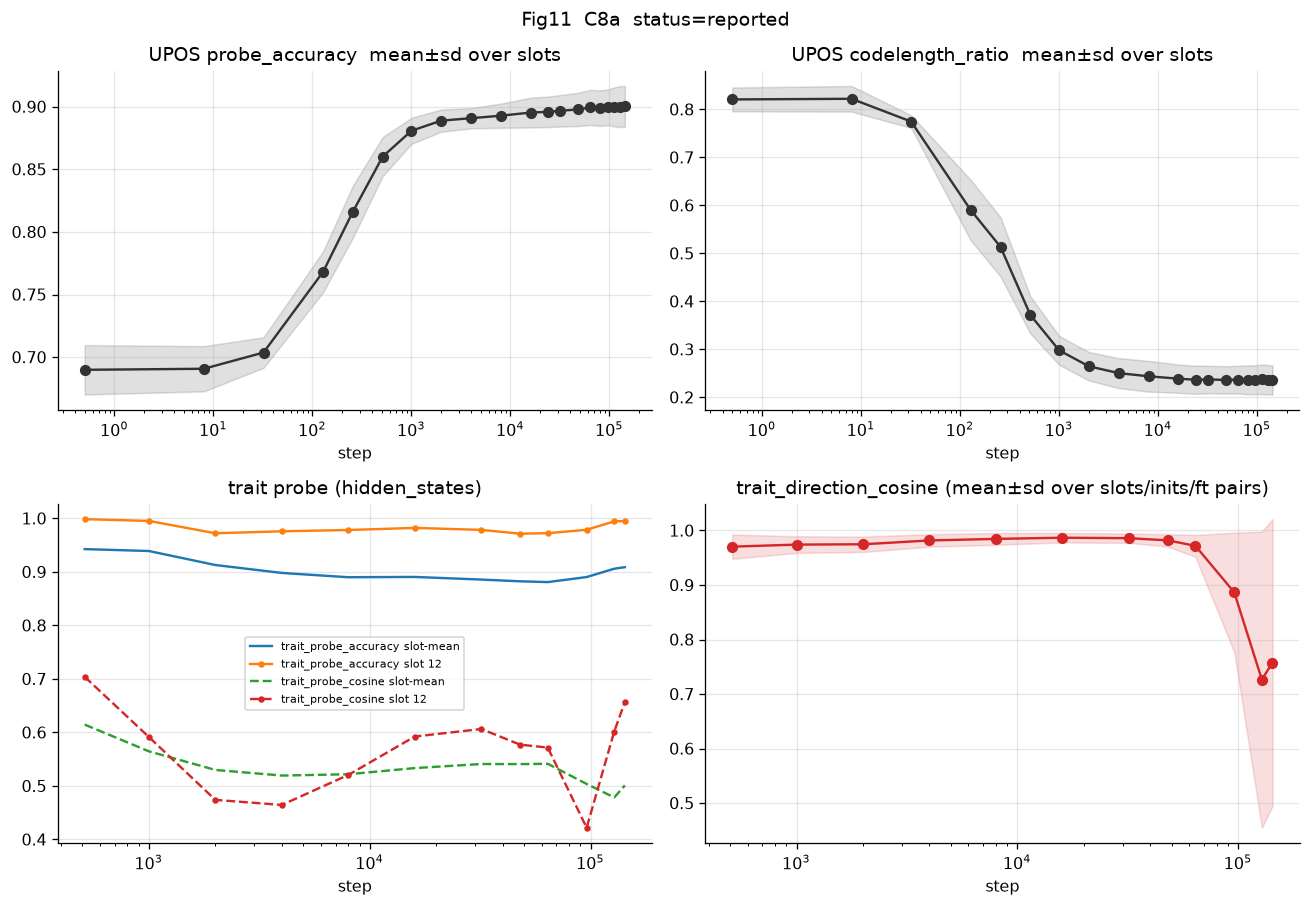

In [15]:
c8 = claim_record("C8")
print("C8 status:", c8.get("status"), "n_probe_rows:", c8.get("n_probe_rows"))
print("probe_metrics (claims):", c8.get("probe_metrics"))
print("ladder_probe_trajectories metrics:", probe_upos["metric"].unique().tolist())
if "task" in probe_upos.columns:
    print("UPOS task:", probe_upos["task"].unique().tolist(), "n_examples:", probe_upos["n_examples"].unique().tolist() if "n_examples" in probe_upos.columns else None)

upos = one_convention(probe_upos, "upos", CONVENTION)
upos = maybe_slot(upos)
scope(upos, f"UPOS {CONVENTION}")
print(
    "Note: GKD in-training probes are not this table. "
    "Per-leaf training_metrics.jsonl exists under cat/ but C8a is UPOS grounding."
)

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.0))
for ax, metric in zip((axes[0, 0], axes[0, 1]), ("probe_accuracy", "codelength_ratio"), strict=True):
    sub = upos[upos["metric"] == metric]
    g = sub.groupby("step")["value"].agg(["mean", "std", "count"]).sort_index()
    x = [step_x(s) for s in g.index]
    ax.plot(x, g["mean"], marker="o", color="0.2")
    ax.fill_between(
        x, g["mean"] - g["std"], g["mean"] + g["std"], color="0.2", alpha=0.15,
    )
    ax.set_xscale("log")
    ax.set_title(f"UPOS {metric}  mean±sd over slots")
    ax.set_xlabel("step")

if probe_trait is None:
    print("SCOPE gap: probe_trait.csv missing")
else:
    pt = one_convention(probe_trait, "probe_trait", TRAIT_CONVENTION)
    pt = maybe_slot(pt)
    scope(pt, f"probe_trait {TRAIT_CONVENTION}")
    ax = axes[1, 0]
    for metric, ls in (("trait_probe_accuracy", "-"), ("trait_probe_cosine", "--")):
        sub = pt[pt["metric"] == metric]
        last = sub[sub["slot"].astype(int) == 12]
        mean_all = sub.groupby("step")["value"].mean().sort_index()
        ax.plot(mean_all.index.map(step_x), mean_all.values, ls=ls, label=f"{metric} slot-mean")
        if not last.empty:
            last_m = last.groupby("step")["value"].mean().sort_index()
            ax.plot(last_m.index.map(step_x), last_m.values, ls=ls, marker="o", ms=3, label=f"{metric} slot 12")
    ax.set_xscale("log")
    ax.set_title("trait probe (hidden_states)")
    ax.legend(fontsize=7)
    ax.set_xlabel("step")

if trait_stab is None:
    print("SCOPE gap: trait_vector_stability.csv missing")
else:
    ts = one_convention(trait_stab, "trait_stab", TRAIT_CONVENTION)
    ts = maybe_slot(ts)
    scope(ts, "trait_vector_stability")
    print("ftseed pairs:", ts.groupby(["ftseed_a", "ftseed_b"]).size().to_dict())
    ax = axes[1, 1]
    g = ts.groupby("step")["value"].agg(["mean", "std"]).sort_index()
    x = [step_x(s) for s in g.index]
    ax.plot(x, g["mean"], marker="o", color=FAMILY_COLORS["data"])
    ax.fill_between(x, g["mean"] - g["std"], g["mean"] + g["std"], color=FAMILY_COLORS["data"], alpha=0.15)
    ax.set_xscale("log")
    ax.set_title("trait_direction_cosine (mean±sd over slots/inits/ft pairs)")
    ax.set_xlabel("step")
fig.suptitle(f"Fig11  C8a  status={c8.get('status')}")
plt.tight_layout()
plt.show()


## 13. Fig12 — Metric grading (C8b)

**What this measures.** `spearman_vs_probe_accuracy` from
`ladder_metric_grading`. Signs: CKA similarity vs probe acc is typically
**negative** (CKA falls as probes rise); SSA **positive**. No CCA row
(`include_cca: false`). The CSV means CKA/Procrustes/SSA across **both**
slot conventions before Spearman; this cell plots the table as stored.


SCOPE: n=5 | metric=5 | ladder_metric_grading
                         metric  n_rungs  rung_span  spearman_vs_probe_accuracy  n_shared_rungs
                  minibatch_cka       20   0.425472                   -0.905263              20
minibatch_cka_highnorm_excluded       20   0.310861                   -0.733835              20
                     procrustes       20   0.693786                    0.705263              20
                            ssa       20  46.584227                    0.995489              20
               trait_coordinate       12   0.251737                   -0.650350              12
CCA present: False


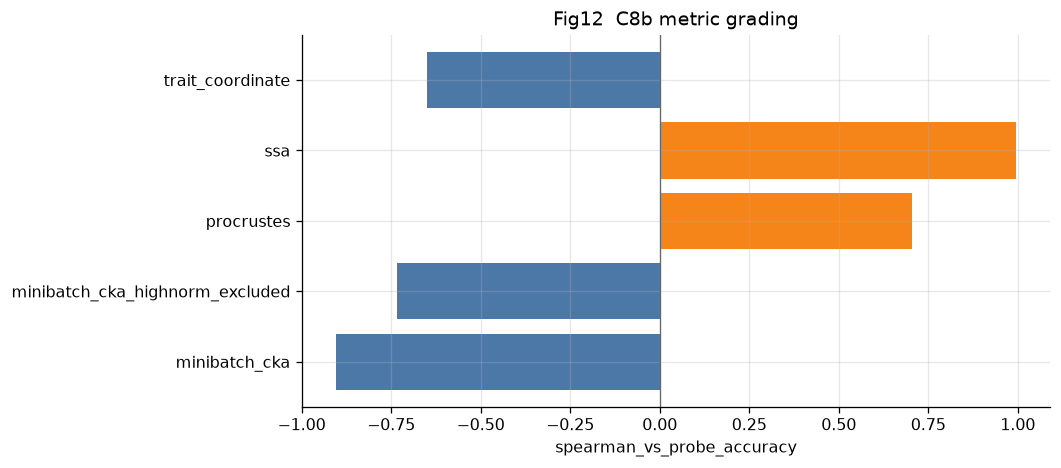

In [16]:
scope(grade, "ladder_metric_grading")
print(grade.to_string(index=False))
print("CCA present:", any("cca" in str(m).lower() for m in grade["metric"]))

fig, ax = plt.subplots(figsize=(8.4, 4.2))
order = list(grade["metric"])
colors = ["#4c78a8" if v < 0 else "#f58518" for v in grade["spearman_vs_probe_accuracy"]]
ax.barh(order, grade["spearman_vs_probe_accuracy"], color=colors)
ax.axvline(0.0, color="0.4", lw=0.8)
ax.set_xlabel("spearman_vs_probe_accuracy")
ax.set_title("Fig12  C8b metric grading")
plt.show()


## 14. Fig13 — Weight space (C9) and Madl coverage

**What this measures.** Frankle barrier vs step; interpolation loss vs α
faceted by rung (`ladder_weight_space` — **no `coverage` column**). Then
per-leaf `first_step_coverage.jsonl` globbed **in memory** (not written back).
Join to `y` via `canonical_label` + rung parsed from the label (`jsonl.step`
is the optimizer step, usually 1). Finite shared-init rows only; note
`basis_broken` skips. Leaf `coverage` is scattered against **pairing-level**
`y` (seeds already averaged); the **pairing-mean** Spearman is the
comparable number.


C9 status: reported n_rows: 144 n_finite: 144
metrics: ['frankle_barrier', 'interp_loss_alpha0', 'interp_loss_alpha0.25', 'interp_loss_alpha0.5', 'interp_loss_alpha0.75', 'interp_loss_alpha1']
wspace columns: ['animal', 'model_a', 'model_b', 'base_revision', 'step', 'basis_validity', 'metric', 'value', 'skip_reason', 'n_tensors']
coverage in CSV: False
SCOPE: n=144 | animal=1 | step=3 | metric=6 | ladder_weight_space
animal NA?: True basis: ['basis_diverged']
steps: [2000, 16000, 143000]


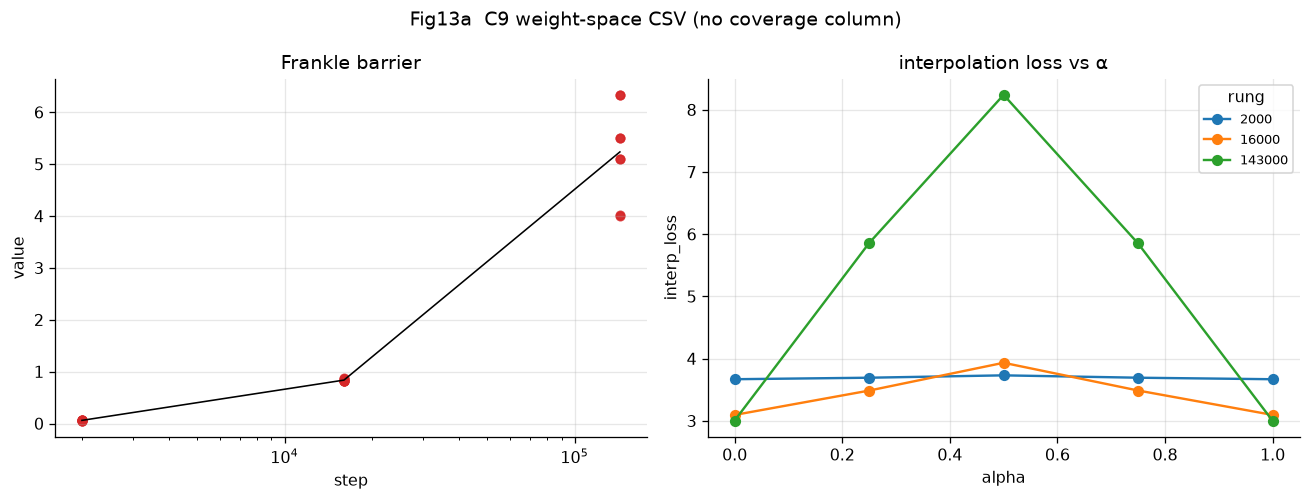

first_step_coverage.jsonl files: 1008
coverage rows: 1008 skip_reason: {nan: 660, 'basis_broken': 348}
jsonl.step unique (optimizer step, not rung): [1]
finite coverage rows: 660 shared-init finite: 660 basis_broken skips: 348
SCOPE: n=660 | cell=2 | family=2 | step=12 | coverage vs y (finite shared-init)
Spearman(coverage, y) leaves: 0.3567059638167306 n= 660 pvalue 3.0937827669530845e-21
Spearman(coverage, y) pairing-mean: 0.2512161877436274 n= 180


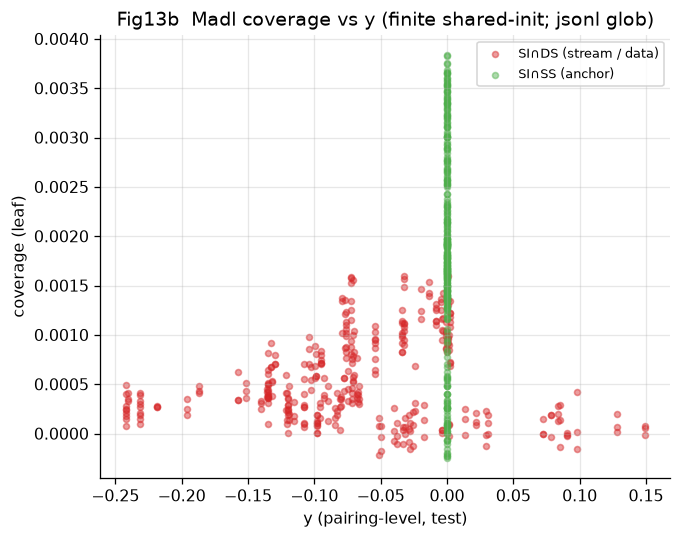

In [17]:
c9 = claim_record("C9")
print("C9 status:", c9.get("status"), "n_rows:", c9.get("n_rows"), "n_finite:", c9.get("n_finite_values"))
print("metrics:", c9.get("metrics"))
print("wspace columns:", list(wspace.columns))
print("coverage in CSV:", "coverage" in wspace.columns)
scope(wspace, "ladder_weight_space")
print("animal NA?:", wspace["animal"].isna().all(), "basis:", wspace["basis_validity"].unique().tolist())
print("steps:", sorted(int(s) for s in wspace["step"].unique()))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
bar = wspace[wspace["metric"] == "frankle_barrier"].copy()
bar = add_step_x(bar)
axes[0].scatter(bar["x"], bar["value"], s=28, alpha=0.8, color=FAMILY_COLORS["data"])
g = bar.groupby("x")["value"].mean()
axes[0].plot(g.index, g.values, color="k", lw=1)
axes[0].set_xscale("log")
axes[0].set_title("Frankle barrier")
axes[0].set_xlabel("step")
axes[0].set_ylabel("value")

interp = wspace[wspace["metric"].astype(str).str.startswith("interp_loss_alpha")].copy()
interp["alpha"] = interp["metric"].str.replace("interp_loss_alpha", "", regex=False).astype(float)
for rung, sub in interp.groupby("step"):
    g = sub.groupby("alpha")["value"].mean().sort_index()
    axes[1].plot(g.index, g.values, marker="o", label=str(int(rung)))
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("interp_loss")
axes[1].legend(title="rung", fontsize=8)
axes[1].set_title("interpolation loss vs α")
fig.suptitle("Fig13a  C9 weight-space CSV (no coverage column)")
plt.tight_layout()
plt.show()

# In-memory coverage glob (read-only; do not write CSV to output_root).
cov_paths = list(TREE.glob("cat/**/first_step_coverage.jsonl"))
print("first_step_coverage.jsonl files:", len(cov_paths))
cov_rows = []
for path in cov_paths:
    text = path.read_text()
    for line in text.splitlines():
        if line.strip():
            cov_rows.append(json.loads(line))
cov = pd.DataFrame(cov_rows)
print("coverage rows:", len(cov), "skip_reason:", cov["skip_reason"].value_counts(dropna=False).to_dict())
print("jsonl.step unique (optimizer step, not rung):", sorted(cov["step"].unique().tolist())[:10])
cov = cov.rename(columns={"step": "optim_step"})

def _rung_from_label(label: str) -> int:
    _, rev = split_revision(str(label))
    step = revision_step(rev)
    if step is None:
        raise ValueError(f"no step in label {label!r}")
    return int(step)

cov["student"] = [canonical_label(s) for s in cov["student_label"]]
cov["teacher"] = [canonical_label(t) for t in cov["teacher_label"]]
cov["rung"] = [_rung_from_label(s) for s in cov["student_label"]]
cov["cell"] = [str(cell_of(s, t)) for s, t in zip(cov["student"], cov["teacher"], strict=True)]

yp = primary_frame(delta)[
    ["student_init_label", "teacher_init_label", "step", "y", "cell", "family"]
].drop_duplicates()
merged = cov.merge(
    yp,
    left_on=["student", "teacher", "rung"],
    right_on=["student_init_label", "teacher_init_label", "step"],
    how="left",
    suffixes=("", "_y"),
)
finite = merged[merged["coverage"].notna() & merged["y"].notna()].copy()
shared = finite[finite["cell"].isin(["SI_SS", "SI_DS"])]
print(
    "finite coverage rows:", len(finite),
    "shared-init finite:", len(shared),
    "basis_broken skips:", int((cov["skip_reason"] == "basis_broken").sum()),
)
scope(shared, "coverage vs y (finite shared-init)")
if len(shared) >= 3:
    rho = spearmanr(shared["coverage"], shared["y"])
    print("Spearman(coverage, y) leaves:", rho.statistic, "n=", len(shared), "pvalue", rho.pvalue)
    pair_mean = (
        shared.groupby(["student", "teacher", "rung"], dropna=False)
        .agg(coverage=("coverage", "mean"), y=("y", "mean"))
        .reset_index()
    )
    rho2 = spearmanr(pair_mean["coverage"], pair_mean["y"])
    print("Spearman(coverage, y) pairing-mean:", rho2.statistic, "n=", len(pair_mean))

fig, ax = plt.subplots(figsize=(6.4, 5.0))
for cell, sub in shared.groupby("cell"):
    ax.scatter(
        sub["y"], sub["coverage"], s=14, alpha=0.45,
        color=CELL_COLORS.get(cell, "0.4"), label=CELL_LABELS.get(cell, cell),
    )
ax.set_xlabel("y (pairing-level, test)")
ax.set_ylabel("coverage (leaf)")
ax.legend(fontsize=8)
ax.set_title("Fig13b  Madl coverage vs y (finite shared-init; jsonl glob)")
plt.show()


## 15. Fig14 — Layer×layer CKA

**What this measures.** 13×13 `pairs[].cross_layer_cka` from P1
`estimator_diagnostics.json` **shards** (merged file absent; `similarity_pairs`
has same-slot rows only, not a layer grid). Two families × four rungs:
original vs data-seed1 (stream) and original vs weight-seed1 (init); rungs
0, 2000, 16000, 143000; convention `post_block`. Heatmaps: magma, origin
lower (CKA notebook). **Colour is CKA, not divergence:** light / yellow =
CKA near **1** (same example-similarity structure); dark / purple = CKA
near **0** (unrelated). Scale is fixed \([0, 1]\) (shared colorbar).
Missing shard/pair → blank panel and a SCOPE gap; **no NaN fill**.


Fig14 panels found: 8 / 8


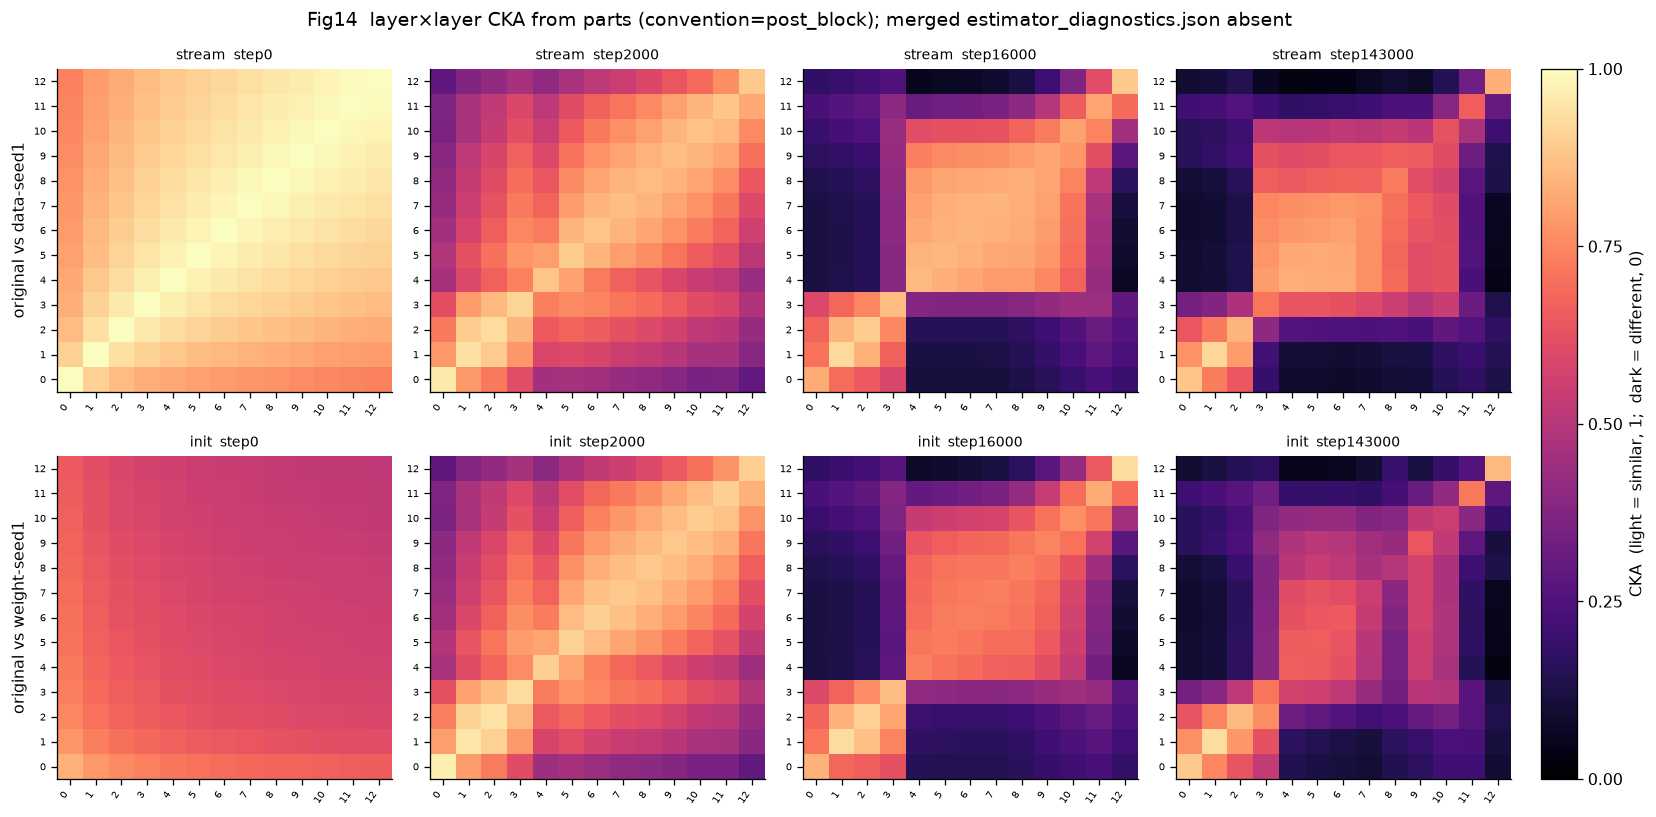

In [18]:
FIG14_RUNGS = (0, 2000, 16000, 143000)
FIG14_PAIRS = (
    ("stream", "original", "data-seed1"),
    ("init", "original", "weight-seed1"),
)

def _cross_layer(step: int, lab_a: str, lab_b: str, convention: str):
    want = frozenset({lab_a, lab_b})
    n_seen = 0
    for path, blob in iter_p1_diagnostics(convention):
        if blob.get("slot_convention") != convention:
            continue
        for item in blob.get("pairs") or []:
            if int(item.get("step")) != int(step):
                continue
            n_seen += 1
            got = frozenset(canonical_label(x) for x in item["pair"])
            if got == want and "cross_layer_cka" in item:
                return np.asarray(item["cross_layer_cka"], dtype=float), path
    return None, None

fig, axes = plt.subplots(2, 4, figsize=(14.0, 7.2))
last_im = None
n_found = 0
for r, (fam, a, b) in enumerate(FIG14_PAIRS):
    for c, rung in enumerate(FIG14_RUNGS):
        ax = axes[r][c]
        mat, src = _cross_layer(rung, a, b, CONVENTION)
        if mat is None:
            print(f"SCOPE gap: no cross_layer_cka for {a} vs {b} at step {rung} ({CONVENTION})")
            ax.set_facecolor("#f0f0f0")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(f"{fam} step{rung}\nmissing", fontsize=9)
            continue
        n_found += 1
        if mat.shape != (13, 13):
            print(f"SCOPE gap: unexpected shape {mat.shape} for {a}/{b} step {rung}")
        grid = pd.DataFrame(mat, index=range(mat.shape[0]), columns=range(mat.shape[1]))
        last_im = aplots.annotated_heatmap(
            ax, grid, cmap="magma", vmin=0.0, vmax=1.0,
            annotate=False, origin="lower", show_ticks=True, tick_fontsize=6,
        )
        ax.set_title(f"{fam}  step{rung}", fontsize=9)
        if c == 0:
            ax.set_ylabel(f"{a} vs {b}")
print(f"Fig14 panels found: {n_found} / {len(FIG14_PAIRS) * len(FIG14_RUNGS)}")
fig.suptitle(
    f"Fig14  layer×layer CKA from parts (convention={CONVENTION}); "
    "merged estimator_diagnostics.json absent"
)
plt.tight_layout()
if last_im is not None:
    cbar = fig.colorbar(last_im, ax=axes, fraction=0.03, pad=0.02)
    cbar.set_ticks([0.0, 0.25, 0.5, 0.75, 1.0])
    cbar.set_label("CKA  (light = similar, 1;  dark = different, 0)")
plt.show()


## 16. Extra views

**What this measures.** Same-slot CKA vs rung heatmap for one pair per family
(not layer×layer); `d_geom` vs `d_trait`; teacher admission `p_target` vs step
(already in §7 — repeated as a compact line); high-norm CKA minus vanilla CKA
when both metrics exist. Optional early/mid/late **slot-band mean** of existing
per-slot CKA rows (slots 0–3 / 4–8 / 9–12) is a **notebook aggregation**, not
`similarity_layer_means.csv`. That band mean pools **all** P1 pairing groups
on this convention (same-init, cyclic, family-swap, …), not one pair.

Same-slot heatmaps use the **same magma \([0, 1]\) CKA scale as Fig14**
(light = similar, dark = different; shared colorbar). Line/scatter panels
keep their existing legends.


SCOPE: n=260 | animal=1 | step=20 | slot=13 | slot_convention=1 | metric=1 | same-slot CKA original vs data-seed1
SCOPE: n=260 | animal=1 | step=20 | slot=13 | slot_convention=1 | metric=1 | same-slot CKA original vs weight-seed1


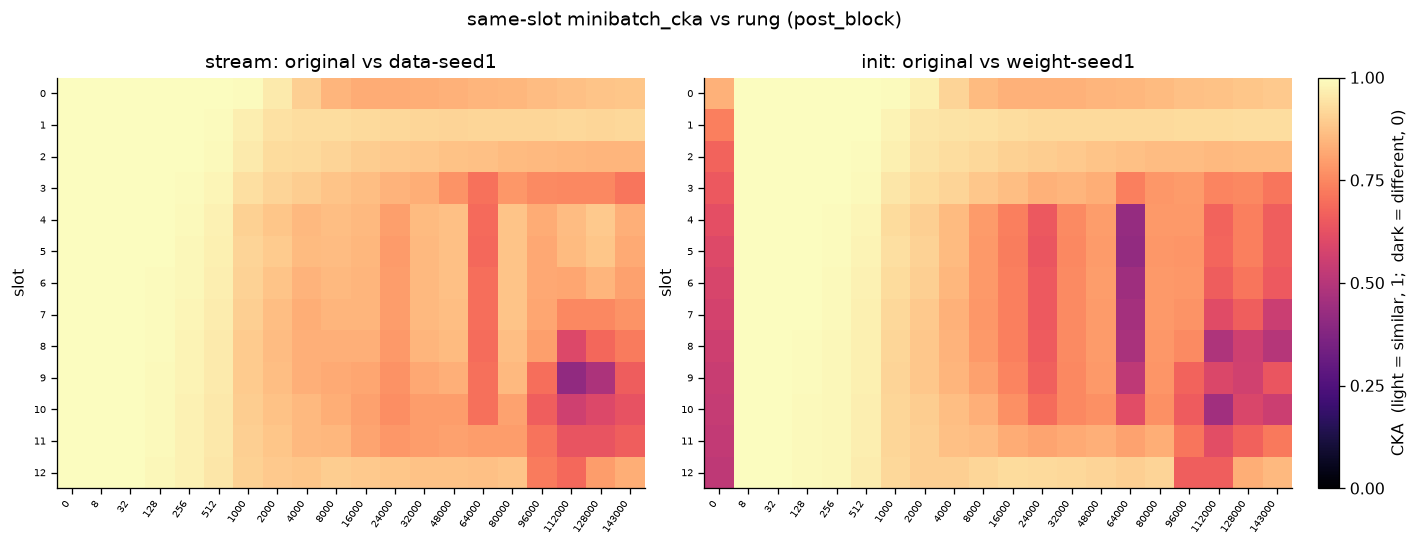

SCOPE: n=60 | step=20 | NOTEBOOK aggregation of per-slot CKA (not a pipeline table)


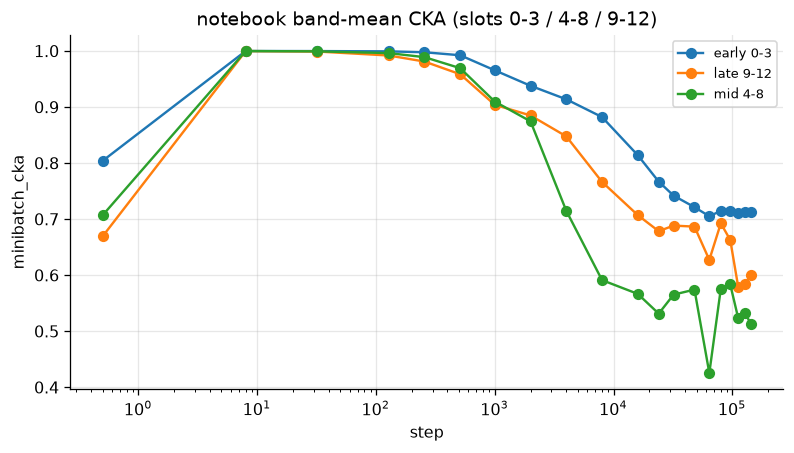

SCOPE: n=192 | animal=1 | set=1 | cell=2 | family=2 | step=12 | slot_convention=1 | pairing_index=16 | d_geom vs d_trait join


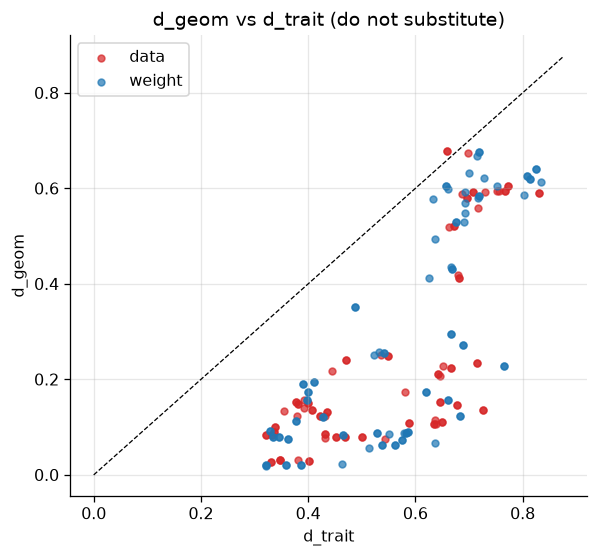

SCOPE: n=5460 | step=20 | slot=13 | high-norm CKA delta (cka − highnorm_excluded)


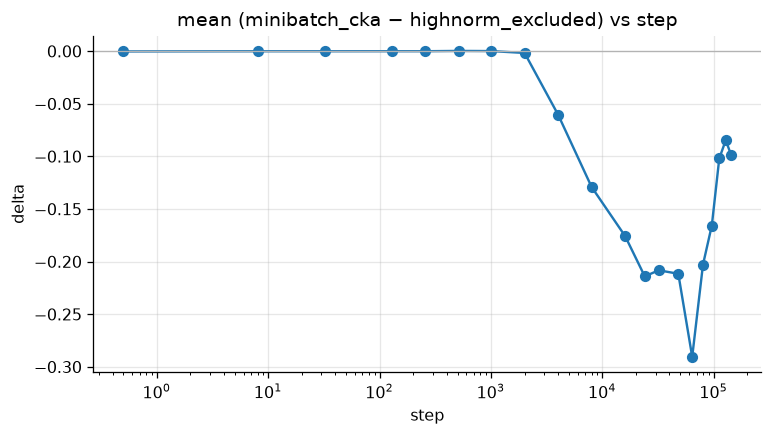

In [19]:
p1 = one_convention(
    sim[sim["metric"].astype(str) == str(plan.Metric.MINIBATCH_CKA)],
    "extra cka",
    CONVENTION,
)
p1 = p1[p1["animal"].isna()].copy()
p1["lab_a"] = [canonical_label(m) for m in p1["model_a"]]
p1["lab_b"] = [canonical_label(m) for m in p1["model_b"]]

def _pair_mask(frame, a, b):
    want = {a, b}
    return [
        {canonical_label(x), canonical_label(y)} == want
        for x, y in zip(frame["lab_a"], frame["lab_b"], strict=True)
    ]

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.8))
last_im = None
for ax, (fam, a, b) in zip(
    axes, (("stream", "original", "data-seed1"), ("init", "original", "weight-seed1")), strict=True,
):
    sub = p1[np.asarray(_pair_mask(p1, a, b))]
    scope(sub, f"same-slot CKA {a} vs {b}")
    grid = sub.pivot_table(index="slot", columns="step", values="value", aggfunc="mean")
    grid = grid.reindex(index=range(13), columns=list(plan.LADDER_G))
    last_im = aplots.annotated_heatmap(
        ax, grid, cmap="magma", vmin=0.0, vmax=1.0, annotate=False,
        origin="upper", tick_fontsize=6,
    )
    ax.set_title(f"{fam}: {a} vs {b}")
    ax.set_ylabel("slot")
fig.suptitle(f"same-slot minibatch_cka vs rung ({CONVENTION})")
plt.tight_layout()
if last_im is not None:
    cbar = fig.colorbar(last_im, ax=axes, fraction=0.03, pad=0.02)
    cbar.set_ticks([0.0, 0.25, 0.5, 0.75, 1.0])
    cbar.set_label("CKA  (light = similar, 1;  dark = different, 0)")
plt.show()

# Notebook-side band mean of existing per-slot rows (NOT similarity_layer_means.csv).
bands = ((0, 3, "early 0-3"), (4, 8, "mid 4-8"), (9, 12, "late 9-12"))
band_rows = []
for lo, hi, name in bands:
    sl = p1[(p1["slot"] >= lo) & (p1["slot"] <= hi)]
    g = sl.groupby("step")["value"].mean()
    for step, val in g.items():
        band_rows.append({"step": int(step), "band": name, "cka": float(val), "n": int((sl["step"] == step).sum())})
band = pd.DataFrame(band_rows)
scope(band, "NOTEBOOK aggregation of per-slot CKA (not a pipeline table)")
fig, ax = plt.subplots(figsize=(8.0, 4.0))
for name, sub in band.groupby("band"):
    ax.plot(sub["step"].map(step_x), sub["cka"], marker="o", label=name)
ax.set_xscale("log")
ax.legend(fontsize=8)
ax.set_title("notebook band-mean CKA (slots 0-3 / 4-8 / 9-12)")
ax.set_xlabel("step")
ax.set_ylabel("minibatch_cka")
plt.show()

# d_geom vs d_trait at pairing level (test divergence d_trait; P1 CKA d_geom).
dprim = primary_frame(div)
dprim = dprim[dprim["family"].isin(["data", "weight"])].copy()
p1f = with_init_labels(one_convention(
    sim[sim["metric"].astype(str) == str(plan.Metric.MINIBATCH_CKA)],
    "d_geom join", CONVENTION,
))
p1f = p1f[p1f["animal"].isna()]
p1f = maybe_slot(p1f)
p1f = attach_family_undirected(p1f)
p1f = p1f[p1f["family"].isin(["data", "weight"])]
def _pair_key(s, t) -> tuple[str, str]:
    a, b = canonical_label(str(s)), canonical_label(str(t))
    return (a, b) if a <= b else (b, a)

geom_pair = p1f.copy()
geom_pair["pair"] = [
    _pair_key(s, t)
    for s, t in zip(geom_pair["student_init_label"], geom_pair["teacher_init_label"], strict=True)
]
geom_pair = (
    geom_pair.groupby(["pair", "step"], dropna=False)["value"]
    .mean()
    .reset_index()
    .rename(columns={"value": "cka"})
)
geom_pair["d_geom"] = 1.0 - geom_pair["cka"]
djoin = dprim.copy()
djoin["pair"] = [
    _pair_key(s, t)
    for s, t in zip(djoin["student_init_label"], djoin["teacher_init_label"], strict=True)
]
joined = djoin.merge(geom_pair, on=["pair", "step"], how="inner")
scope(joined, "d_geom vs d_trait join")
fig, ax = plt.subplots(figsize=(5.8, 5.2))
for fam, sub in joined.groupby("family"):
    ax.scatter(
        sub["d_trait"], sub["d_geom"], s=18, alpha=0.7,
        color=FAMILY_COLORS.get(str(fam), "0.4"), label=str(fam),
    )
lims = [
    0.0,
    float(max(joined["d_trait"].max(), joined["d_geom"].max())) * 1.05,
]
ax.plot(lims, lims, "k--", lw=0.8)
ax.set_xlabel("d_trait")
ax.set_ylabel("d_geom")
ax.legend()
ax.set_title("d_geom vs d_trait (do not substitute)")
plt.show()

# High-norm CKA delta (vanilla − highnorm_excluded), P1 post_block.
hn = one_convention(
    sim[sim["metric"].astype(str) == "minibatch_cka_highnorm_excluded"],
    "highnorm", CONVENTION,
)
hn = hn[hn["animal"].isna()]
hn = maybe_slot(hn)
cka = one_convention(
    sim[sim["metric"].astype(str) == str(plan.Metric.MINIBATCH_CKA)],
    "cka hn join", CONVENTION,
)
cka = cka[cka["animal"].isna()]
cka = maybe_slot(cka)
keys = ["model_a", "model_b", "step", "slot"]
m = cka[keys + ["value"]].merge(
    hn[keys + ["value"]], on=keys, suffixes=("_cka", "_hn")
)
m["delta"] = m["value_cka"] - m["value_hn"]
scope(m, "high-norm CKA delta (cka − highnorm_excluded)")
g = m.groupby("step")["delta"].mean().sort_index()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(g.index.map(step_x), g.values, marker="o")
ax.axhline(0.0, color="0.7", lw=0.8)
ax.set_xscale("log")
ax.set_title("mean (minibatch_cka − highnorm_excluded) vs step")
ax.set_xlabel("step")
ax.set_ylabel("delta")
plt.show()


## 16b. Checkpoint-SL views (same-rung)

**What this measures.** Behavioural heatmaps that the line plots in Fig2 / Fig4
do not make easy to read: which of the **23 same-rung pairings** transfer, at
which pretraining step, and whether that is a late-rung ceiling or a faster
GKD rise. Primary endpoint is still `test` / `prob` (`primary_frame`).

**Not computed (absent on disk).** A teacher×student *checkpoint* grid
(teacher `@stepT` × student `@stepS` for `T ≠ S`). Every trained pair is
`student@stepK` with `teacher@stepK`. The 7×7 panels below are **init × init
at a fixed rung**; blank cells are unrun (no DI∩DS), not zero.

Does not change C1–C9. Complements Fig2 (gap vs log step), Fig4 (SI∩SS
emergence), and Fig6 (teacher `p_target` vs step).


SCOPE: n=276 | animal=1 | set=1 | cell=3 | family=3 | step=12 | pairing_index=23 | §16b PRIMARY test/prob
teacher step == student step (no T×S checkpoint grid): True cross-rung rows: 0
cells: {'SI_DS': 96, 'DI_SS': 96, 'SI_SS': 84} (no DI_DS)
n pairing×rung: 276 expected 276
pairing heatmap NaNs (should be 0): 0 0
delta range 0.0061337350668569 0.4372926307855717 | y range -0.2419841374123157 0.1489102292091896


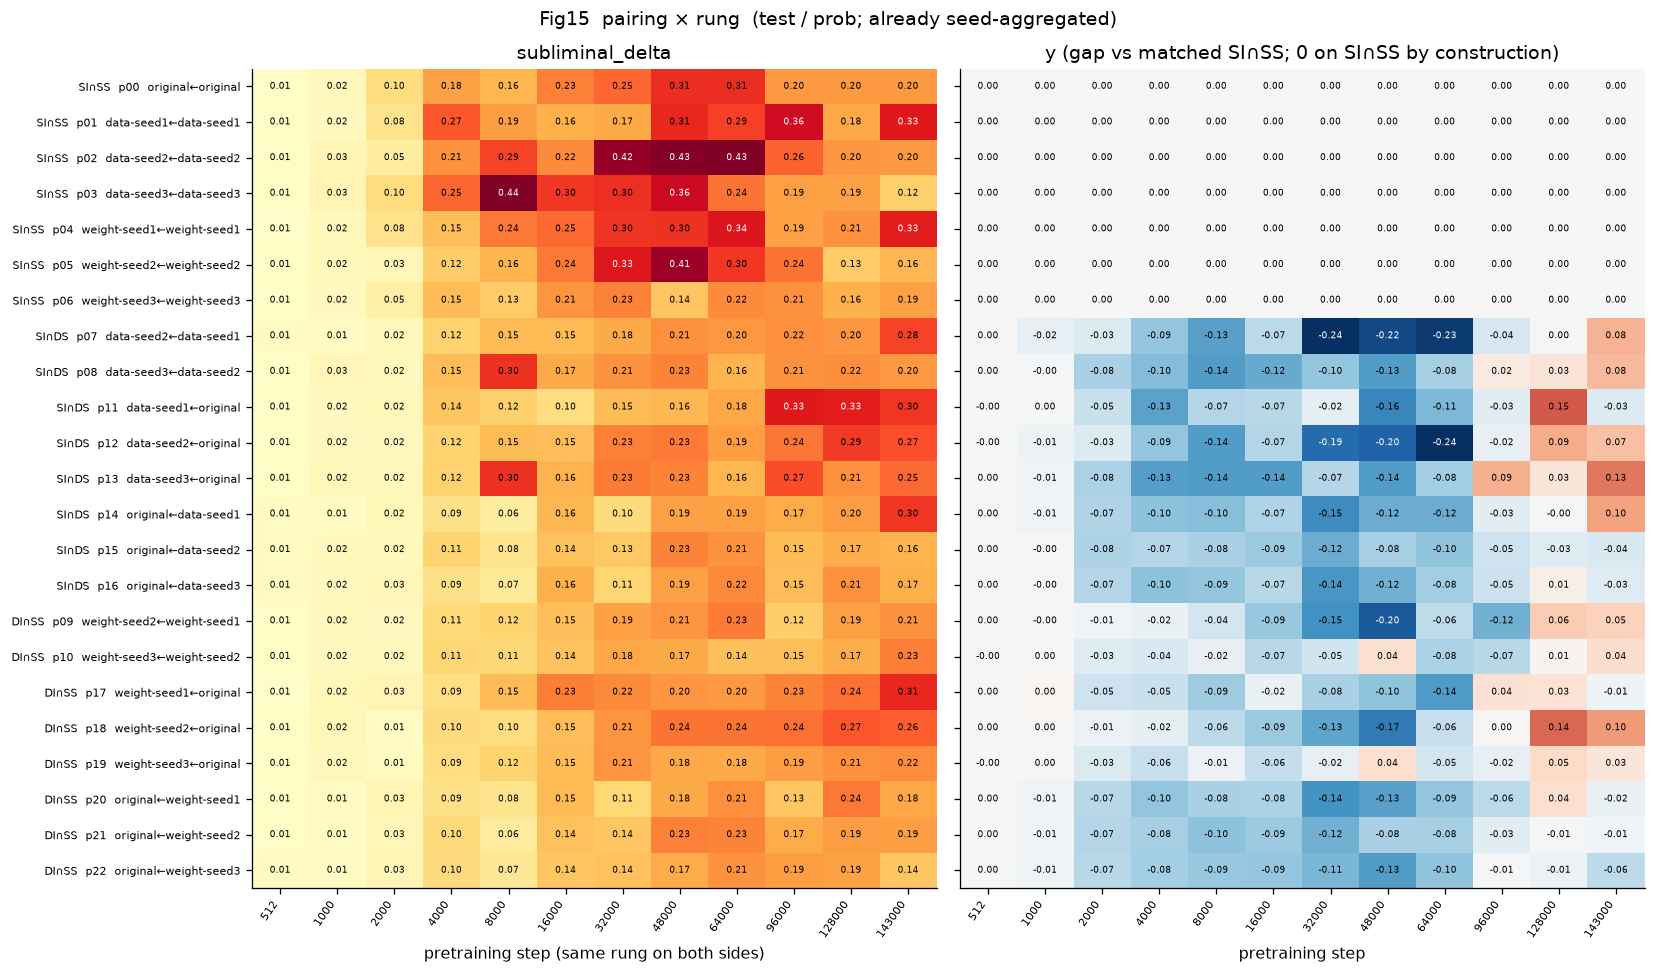

init×init filled pairings: 23/49 (blank = unrun)


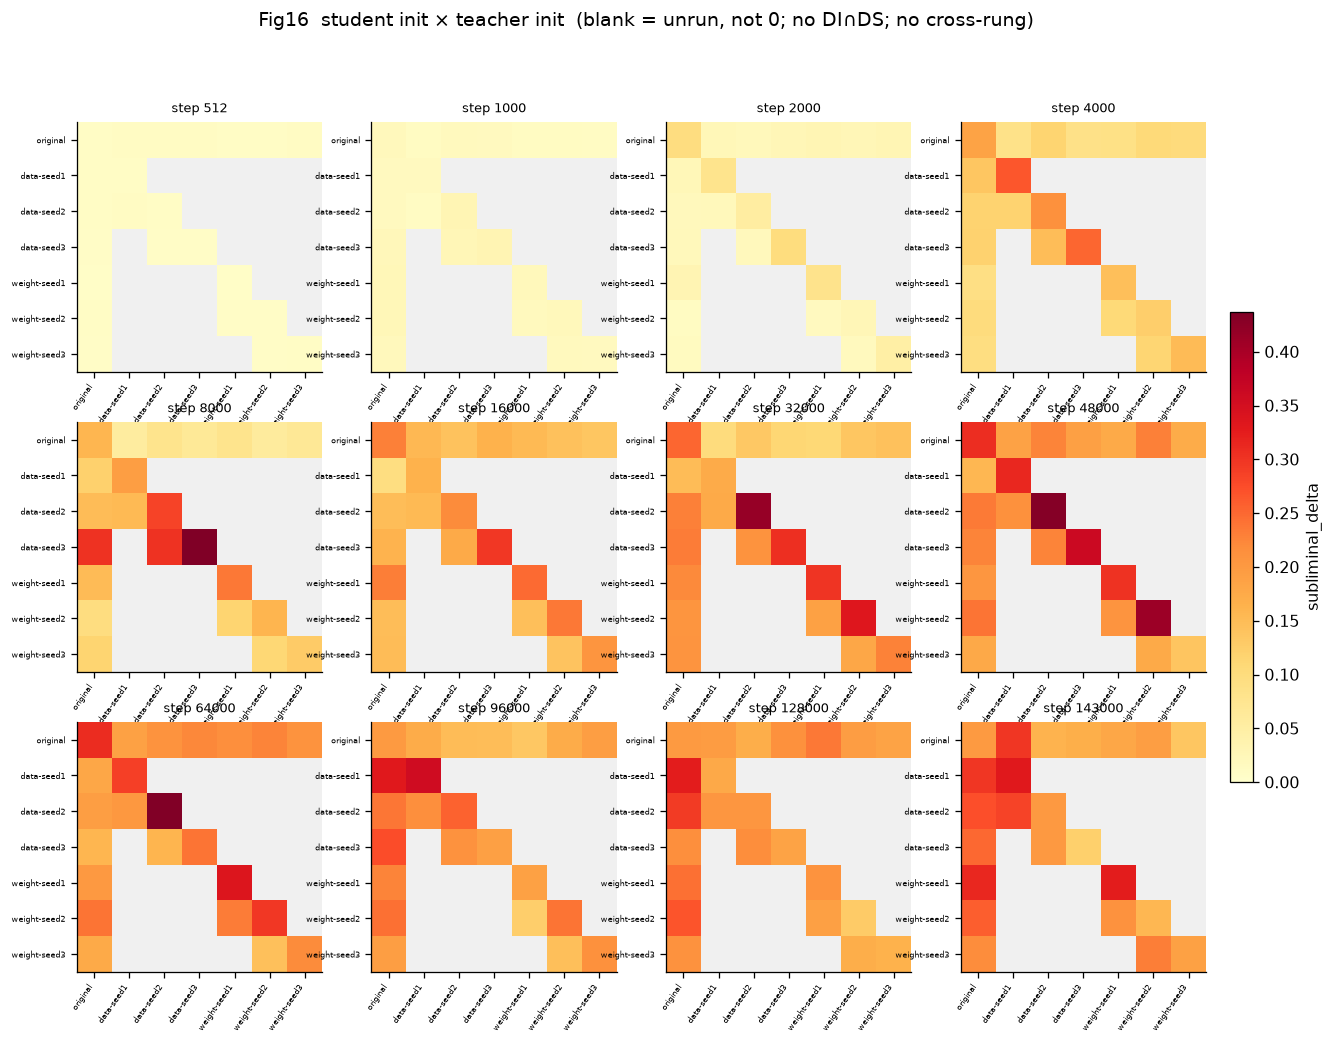

In [20]:
from matplotlib.colors import TwoSlopeNorm
from subliminal_learning.evaluation.gkd_results_io import load_gkd_probe_trajectories

CELL_ORDER = ("SI_SS", "SI_DS", "DI_SS")
CELL_SHORT = {"SI_SS": "SI∩SS", "SI_DS": "SI∩DS", "DI_SS": "DI∩SS"}


def _cmap_bad(name: str, bad: str = "#f0f0f0"):
    cmap = plt.get_cmap(name).copy()
    cmap.set_bad(bad)
    return cmap


def _pair_label(cell, pairing_index, student, teacher) -> str:
    return f"{CELL_SHORT[str(cell)]}  p{int(pairing_index):02d}  {student}←{teacher}"


prim16 = primary_frame(delta)
scope(prim16, "§16b PRIMARY test/prob")
if prim16.empty:
    raise RuntimeError("primary test/prob frame is empty — cannot draw §16b")
def _rev_step(label) -> int | None:
    _, rev = split_revision(str(label))
    return revision_step(rev)


_stu_step = [_rev_step(m) for m in prim16["model"]]
_tch_step = [
    _rev_step(t) if pd.notna(t) else s
    for t, s in zip(prim16["teacher_base_label"], _stu_step, strict=True)
]
_n_cross = sum(a != b for a, b in zip(_stu_step, _tch_step, strict=True))
print("teacher step == student step (no T×S checkpoint grid):", _n_cross == 0, "cross-rung rows:", _n_cross)
print("cells:", prim16["cell"].value_counts().to_dict(), "(no DI_DS)")
print("n pairing×rung:", len(prim16), "expected", 23 * 12)

pairs16 = ladder_pairs()
pair_order = []
for cell in CELL_ORDER:
    for p in pairs16:
        if p.cell.value == cell:
            pair_order.append(_pair_label(cell, p.index, p.student, p.teacher))
hm = prim16.copy()
hm["pair_label"] = [
    _pair_label(c, i, s, t)
    for c, i, s, t in zip(
        hm["cell"], hm["pairing_index"], hm["student_init_label"], hm["teacher_init_label"],
        strict=True,
    )
]
missing = set(pair_order) - set(hm["pair_label"])
if missing:
    raise RuntimeError(f"pairing labels missing from ladder_delta: {sorted(missing)[:5]}")

d_grid = (
    hm.pivot_table(index="pair_label", columns="step", values="subliminal_delta", aggfunc="mean")
    .reindex(index=pair_order, columns=list(plan.LADDER_B))
)
y_grid = (
    hm.pivot_table(index="pair_label", columns="step", values="y", aggfunc="mean")
    .reindex(index=pair_order, columns=list(plan.LADDER_B))
)
print("pairing heatmap NaNs (should be 0):", int(d_grid.isna().sum().sum()), int(y_grid.isna().sum().sum()))
print(
    "delta range", float(d_grid.min().min()), float(d_grid.max().max()),
    "| y range", float(y_grid.min().min()), float(y_grid.max().max()),
)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 8.6), sharey=True)
aplots.annotated_heatmap(
    axes[0], d_grid, cmap="YlOrRd", vmin=0.0, vmax=float(d_grid.max().max()),
    fmt="{:.2f}", origin="upper", tick_fontsize=7, cell_fontsize=5.5,
)
axes[0].set_title("subliminal_delta")
axes[0].set_xlabel("pretraining step (same rung on both sides)")
yabs = float(np.nanmax(np.abs(y_grid.to_numpy())))
aplots.annotated_heatmap(
    axes[1], y_grid, cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-yabs, vcenter=0.0, vmax=yabs),
    fmt="{:.2f}", origin="upper", tick_fontsize=7, cell_fontsize=5.5,
)
axes[1].set_title("y (gap vs matched SI∩SS; 0 on SI∩SS by construction)")
axes[1].set_xlabel("pretraining step")
fig.suptitle("Fig15  pairing × rung  (test / prob; already seed-aggregated)")
plt.tight_layout()
plt.show()

init_order = list(plan.INITS)
vmax_d = float(prim16["subliminal_delta"].max())
fig, axes = plt.subplots(3, 4, figsize=(13.2, 9.6))
last = None
n_filled = prim16.groupby(["student_init_label", "teacher_init_label"]).ngroups
print(f"init×init filled pairings: {n_filled}/49 (blank = unrun)")
for ax, rung in zip(axes.ravel(), plan.LADDER_B, strict=True):
    sub = prim16[prim16["step"] == int(rung)]
    grid = (
        sub.pivot_table(
            index="student_init_label", columns="teacher_init_label",
            values="subliminal_delta", aggfunc="mean",
        )
        .reindex(index=init_order, columns=init_order)
    )
    last = aplots.annotated_heatmap(
        ax, grid, cmap=_cmap_bad("YlOrRd"), vmin=0.0, vmax=vmax_d,
        annotate=False, origin="upper", tick_fontsize=5, empty_facecolor="#f0f0f0",
    )
    ax.set_title(f"step {int(rung)}", fontsize=8)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Fig16  student init × teacher init  (blank = unrun, not 0; no DI∩DS; no cross-rung)")
fig.colorbar(last, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02, label="subliminal_delta")
plt.show()


SCOPE: n=276 | animal=1 | set=1 | cell=3 | family=3 | step=12 | pairing_index=23 | §16b onset / teacher join
control p_target max (all pairings): 0.0088836025433071
SI_SS mean delta by rung:
 step
512       0.0086
1000      0.0224
2000      0.0692
4000      0.1907
8000      0.2284
16000     0.2284
32000     0.2872
48000     0.3231
64000     0.3034
96000     0.2344
128000    0.1808
143000    0.2175
Name: subliminal_delta, dtype: float64


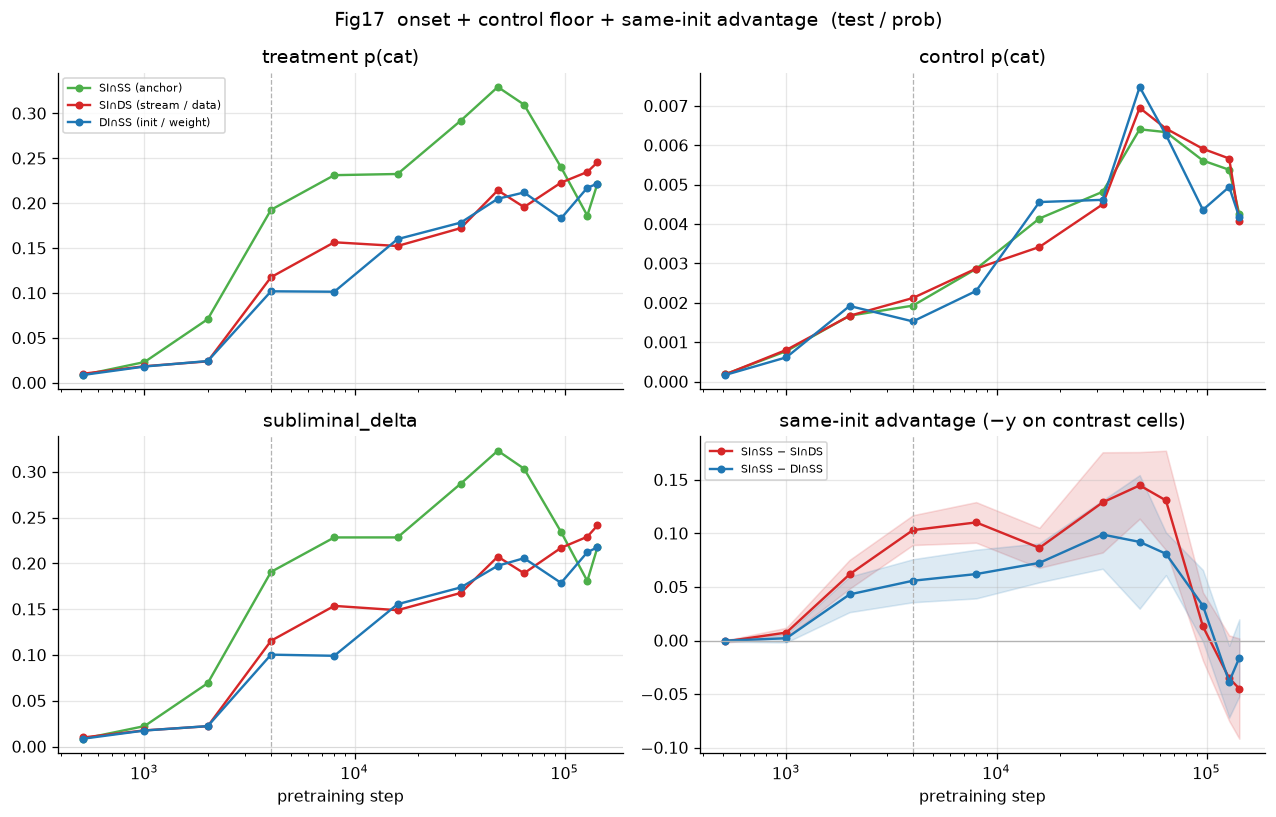

SCOPE: n=276 | animal=1 | set=1 | cell=3 | family=3 | step=12 | pairing_index=23 | §16b teacher_p_target ⋈ student delta
Spearman(teacher_p, delta) all: SignificanceResult(statistic=np.float64(0.6913931016932754), pvalue=np.float64(1.4431687199308179e-40))
Spearman(teacher_p, y) all: SignificanceResult(statistic=np.float64(-0.3724130927304415), pvalue=np.float64(1.6561911687871107e-10))


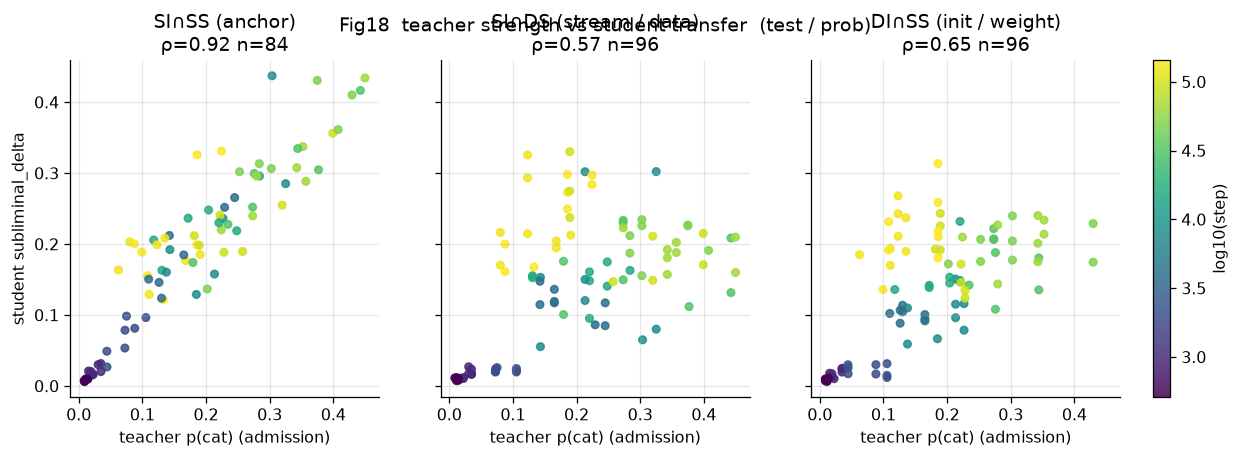

In [21]:
# Onset + control floor + same-init advantage, then teacher-strength scatter.
# Advantage is −y on contrast cells (within-student; prereg y, not a pooled Δ).
scope(prim16, "§16b onset / teacher join")
fig, axes = plt.subplots(2, 2, figsize=(11.2, 7.2), sharex=True)
onset_panels = (
    (axes[0, 0], "p_target_treatment", "treatment p(cat)"),
    (axes[0, 1], "p_target_control", "control p(cat)"),
    (axes[1, 0], "subliminal_delta", "subliminal_delta"),
)
for ax, col, title in onset_panels:
    for cell in CELL_ORDER:
        sub = prim16[prim16["cell"] == cell].groupby("step")[col].mean().sort_index()
        ax.plot(
            sub.index.map(step_x), sub.values, marker="o", ms=4,
            color=CELL_COLORS[cell], label=CELL_LABELS[cell],
        )
    ax.set_xscale("log")
    ax.set_title(title)
    ax.axvline(4000, color="0.7", ls="--", lw=0.8)
    if col != "p_target_control":
        ax.axhline(0.0, color="0.85", lw=0.6)
axes[0, 0].legend(fontsize=7)
ax = axes[1, 1]
for cell in ("SI_DS", "DI_SS"):
    sub = prim16[prim16["cell"] == cell]
    g = sub.groupby("step")["y"].agg(["mean", "std", "count"])
    adv = -g["mean"]
    err = 1.96 * g["std"].fillna(0.0) / np.sqrt(g["count"])
    xs = g.index.map(step_x)
    ax.plot(xs, adv, marker="o", ms=4, color=CELL_COLORS[cell],
            label=f"SI∩SS − {CELL_SHORT[cell]}")
    ax.fill_between(xs, adv - err, adv + err, color=CELL_COLORS[cell], alpha=0.15)
ax.axhline(0.0, color="0.7", lw=0.8)
ax.axvline(4000, color="0.7", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_title("same-init advantage (−y on contrast cells)")
ax.legend(fontsize=7)
for ax in axes[1]:
    ax.set_xlabel("pretraining step")
ctrl_max = float(prim16["p_target_control"].max())
print("control p_target max (all pairings):", ctrl_max)
print("SI_SS mean delta by rung:\n", prim16[prim16["cell"] == "SI_SS"].groupby("step")["subliminal_delta"].mean().round(4))
fig.suptitle("Fig17  onset + control floor + same-init advantage  (test / prob)")
plt.tight_layout()
plt.show()

adm16 = pd.DataFrame(ADMISSION["cells"])
tj = prim16.merge(
    adm16.rename(columns={"rung": "step", "init": "teacher_init_label"}),
    on=["step", "teacher_init_label"], how="left", suffixes=("", "_adm"),
)
if tj["teacher_p_target"].isna().any():
    raise RuntimeError("teacher admission join dropped rows — check init labels")
scope(tj, "§16b teacher_p_target ⋈ student delta")
print(
    "Spearman(teacher_p, delta) all:",
    spearmanr(tj["teacher_p_target"], tj["subliminal_delta"]),
)
print(
    "Spearman(teacher_p, y) all:",
    spearmanr(tj["teacher_p_target"], tj["y"]),
)
fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.8), sharex=True, sharey=True)
sc = None
for ax, cell in zip(axes, CELL_ORDER, strict=True):
    sub = tj[tj["cell"] == cell]
    sc = ax.scatter(
        sub["teacher_p_target"], sub["subliminal_delta"],
        c=np.log10(sub["step"].astype(float)), s=22, alpha=0.85, cmap="viridis",
    )
    rho = spearmanr(sub["teacher_p_target"], sub["subliminal_delta"])
    ax.set_title(f"{CELL_LABELS[cell]}\nρ={rho.statistic:.2f} n={len(sub)}")
    ax.set_xlabel("teacher p(cat) (admission)")
axes[0].set_ylabel("student subliminal_delta")
fig.colorbar(sc, ax=axes.ravel().tolist(), fraction=0.02, pad=0.03, label="log10(step)")
fig.suptitle("Fig18  teacher strength vs student transfer  (test / prob)")
plt.show()


gkd_tag values: {'lmb1.0_b1.0_lora_lr4e-4_e1_r8a16': 32760}
treatment leaves: 1008 diverged: 1
SCOPE: n=26182 | animal=1 | cell=3 | step=26 | §16b in-training p_target (treatment, ~diverged)
GKD steps: [0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625]
rungs: [512, 1000, 2000, 4000, 8000, 16000, 32000, 48000, 64000, 96000, 128000, 143000]
cells: {'DI_SS': 9048, 'SI_DS': 9022, 'SI_SS': 8112}
mean in-training p_target at GKD step 0 by rung:
 rung
512       0.0001
1000      0.0003
2000      0.0011
4000      0.0011
8000      0.0018
16000     0.0026
32000     0.0029
48000     0.0050
64000     0.0041
96000     0.0045
128000    0.0045
143000    0.0035
Name: p_target, dtype: float64
mean in-training p_target at last GKD step by cell×rung:
rung   512     1000    2000    4000    8000    16000   32000   48000   64000   \
cell                                                                            
DI_SS   0.006   0.016 

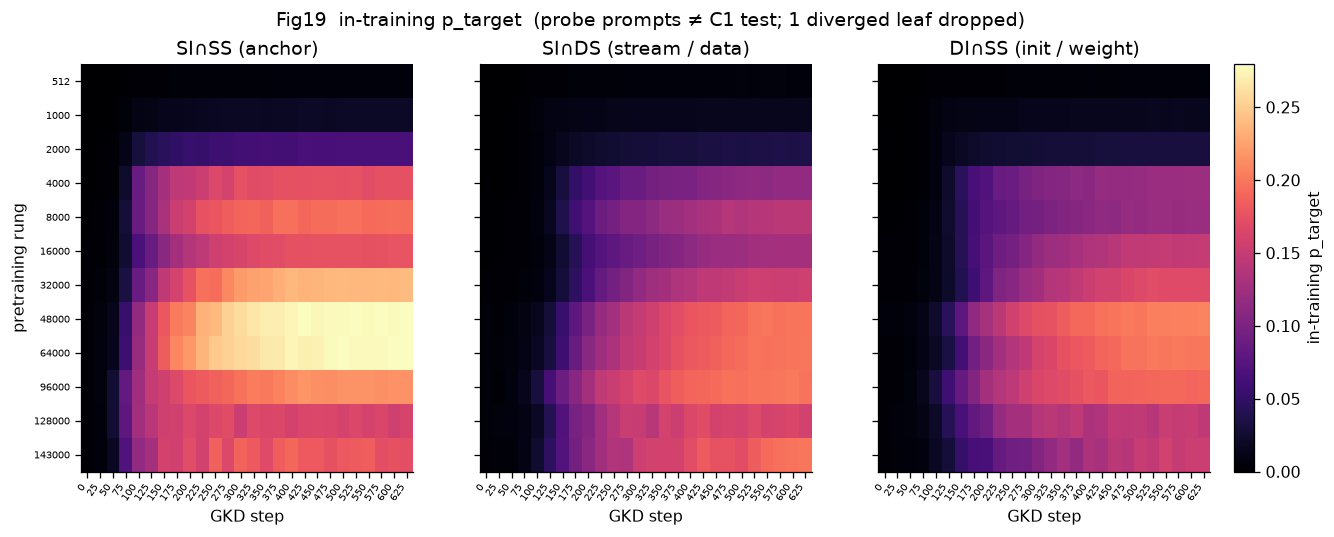

In [22]:
# In-training p_target from per-leaf training_metrics.jsonl (not a results/ table).
# Probe prompts ≠ C1 test set — do not treat last GKD step as preference_eval.
traj = load_gkd_probe_trajectories(
    OUTPUT_ROOT,
    subdir=f"{GKD_STUDENTS_SUBDIR}/{plan.RUN_SET_ID}",
    animals=["cat"],
)
print("gkd_tag values:", traj["gkd_tag"].value_counts().to_dict())
traj = traj[(traj["gkd_tag"] == plan.STUDENT_GKD_TAG) & (~traj["is_control"])].copy()
traj["rung"] = [revision_step(split_revision(str(m))[1]) for m in traj["model"]]
if traj["rung"].isna().any():
    raise RuntimeError("unparseable student revision in training_metrics leaves")
traj["student"] = [canonical_label(m) for m in traj["model"]]
traj["teacher"] = [
    canonical_label(t) if bool(xi) and pd.notna(t) else s
    for s, t, xi in zip(
        traj["student"], traj["teacher_base_label"], traj["teacher_cross_init"], strict=True,
    )
]
traj["cell"] = [str(cell_of(s, t)) for s, t in zip(traj["student"], traj["teacher"], strict=True)]
leaf_div = traj.groupby("run_dir")["diverged"].first()
print("treatment leaves:", int(traj["run_dir"].nunique()), "diverged:", int(leaf_div.sum()))
ok = traj[(~traj["diverged"]) & traj["p_target"].notna()].copy()
scope(ok, "§16b in-training p_target (treatment, ~diverged)")
print("GKD steps:", sorted(int(s) for s in ok["step"].unique()))
print("rungs:", sorted(int(s) for s in ok["rung"].unique()))
print("cells:", ok["cell"].value_counts().to_dict())

gkd_steps = sorted(int(s) for s in ok["step"].unique())
vmax_p = float(ok.groupby(["cell", "rung", "step"])["p_target"].mean().max())
step0 = ok[ok["step"] == 0].groupby("rung")["p_target"].mean()
print("mean in-training p_target at GKD step 0 by rung:\n", step0.round(4))
print("mean in-training p_target at last GKD step by cell×rung:")
print(ok[ok["step"] == max(gkd_steps)].groupby(["cell", "rung"])["p_target"].mean().unstack().round(3))

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.6), sharey=True)
last = None
for ax, cell in zip(axes, CELL_ORDER, strict=True):
    sub = ok[ok["cell"] == cell]
    grid = (
        sub.pivot_table(index="rung", columns="step", values="p_target", aggfunc="mean")
        .reindex(index=list(plan.LADDER_B), columns=gkd_steps)
    )
    last = aplots.annotated_heatmap(
        ax, grid, cmap="magma", vmin=0.0, vmax=vmax_p, annotate=False,
        origin="upper", tick_fontsize=6,
    )
    ax.set_title(CELL_LABELS[cell])
    ax.set_xlabel("GKD step")
axes[0].set_ylabel("pretraining rung")
fig.suptitle("Fig19  in-training p_target  (probe prompts ≠ C1 test; 1 diverged leaf dropped)")
fig.colorbar(last, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02, label="in-training p_target")
plt.show()


### Reading this figure

These five panels are the same-rung campaign on disk. They do **not** support a teacher-step × student-step grid.

### Fig15 — pairing × rung

**Question it answers.** At which pretraining step, and for which of the 23 pairings, does cat-preference transfer appear — and is the same-init pairing still ahead?

**Axes.** x = Ladder-B rung (teacher and student are both `@stepK`). y = pairing, grouped SI∩SS / SI∩DS / DI∩SS. Left: `subliminal_delta`. Right: `y` (0 on SI∩SS by construction).

**How the metric is calculated.** `ladder_delta.csv` already seed-aggregated; `primary_frame` (`test` / `prob`). `subliminal_delta = p_target_treatment − p_target_control`. `y = delta(pair) − delta(SI∩SS, same student, same rung, same set)`.

**What we see.** Scope n=276 (23×12). Left: near-zero through 1000; a jump 2000→4000; SI∩SS darkest mid-ladder (cell-mean peak 0.323 at 48000; max pairing 0.437 at `data-seed3←data-seed3` @ 8000) then a decline. SI∩DS / DI∩SS keep rising and catch SI∩SS by 128000. Right: mid-ladder blue (worst `y` −0.242 at `data-seed2←original` @ 64000); some stream cells flip red late (max +0.149 at `data-seed1←original` @ 128000).

**What to infer.** Transfer is a mid-pretraining phenomenon on this recipe, strongest on the matched pairing, and the matched *advantage* shrinks late — the same U-shape as Fig2. This does not decide C1 (that is `y` vs `d_trait` on admitted rungs). 512 stays in the figure (C3 includes it; C1 drops it).

### Fig16 — init × init per rung

**Question it answers.** Which student-init × teacher-init cells were actually trained, and does the 4k jump show up on the diagonal and the `original` cross?

**Axes.** 3×4 panels = 12 rungs. Each panel is student init (y) × teacher init (x). Shared `subliminal_delta` colour. Grey = unrun.

**How the metric is calculated.** Same `test` / `prob` pairing rows as Fig15, pivoted. 23 of 49 cells exist; DI∩DS and all `T≠S` checkpoint pairs are absent.

**What we see.** 23/49 filled. 512–2000 stay pale. Colour appears at 4000 on the diagonal and the `original` column. Mid-ladder (32k–64k) is the darkest. Late rungs stay filled but the diagonal no longer dominates.

**What to infer.** This is the structural analog of a T×S *checkpoint* grid, with **init** on both axes. Do not read a grey cell as “no transfer.”

### Fig17 — onset, control floor, same-init advantage

**Question it answers.** Is the 4k jump a moving control floor, and when does same-init stop helping?

**Axes.** x = pretraining step (log). Dashed vertical at 4000. Green SI∩SS, red SI∩DS, blue DI∩SS. Bottom-right is `−y` on contrast cells (within-student), not a pooled Δ difference.

**How the metric is calculated.** Means over pairings in `primary_frame`. Control is the matched base-teacher student. Band is ±1.96 SE across pairings.

**What we see.** Treatment `p(cat)` and `subliminal_delta` share the 4k jump; SI∩SS peaks ~0.33 at 48000 then falls. Control max is 0.0089 — ~20× the 512 floor, still <0.01. Same-init advantage is ~0 early, largest mid-ladder (stream gap ~0.15 at 48000), and ~0 / slightly negative by 128000–143000.

**What to infer.** Raw `p_target` must not be compared across rungs without the control, but the control does not create the 4k jump. Late convergence of `y` is recovery of the *mismatched* cells plus a decline of SI∩SS, not a new currency result.

### Fig18 — teacher strength vs student transfer

**Question it answers.** Is student `subliminal_delta` just teacher `p(cat)`?

**Axes.** x = admission `teacher_p_target` (one value per init×rung). y = pairing-level `subliminal_delta`. Colour = log10(step). One panel per cell.

**How the metric is calculated.** Left-join of `teacher_admission_report.json` (84 cells) onto the 276 primary rows on `(step, teacher_init_label)`. Spearman on each cell.

**What we see.** SI∩SS ρ=0.92 (n=84): matched transfer tracks teacher strength. SI∩DS ρ=0.57 (n=96); DI∩SS ρ=0.65 (n=96). Overall Spearman vs `y` is −0.37: late rungs have stronger teachers *and* a smaller transfer gap.

**What to infer.** Teacher strength is a real confound for matched Δ (and for C5-adjacent readings of mid-ladder). It does not by itself explain why `y` recovers late. Admission remains labelling-only; 512 is still trained.

### Fig19 — GKD step × pretraining rung

**Question it answers.** Do late rungs already start high, or do they acquire `p_target` faster during GKD?

**Axes.** x = GKD optimizer step (0, 25, …, 625). y = pretraining rung. Colour = mean in-training `p_target` over treatment leaves. Three cells.

**How the metric is calculated.** `load_gkd_probe_trajectories` on this run-set (`cat` only). Drops controls, wrong `gkd_tag`, and diverged leaves (`~diverged` before any mean). Student/teacher inits from the model dir + `_tbase-` suffix. **Probe prompts are consensus/favorite, not the C1 `test` set** — last-step colour is not `preference_eval`.

**What we see.** 1007/1008 treatment leaves (1 diverged dropped). GKD step 0 is ~0 on every rung. Rise is faster after rung 4000; SI∩SS 32k–64k hit the highest ceiling; 128k ends lower than 48k. SI∩DS / DI∩SS stay below the SI∩SS mid-ladder peak.

**What to infer.** The 4k jump is learned during GKD, not an init offset. Mid-ladder SI∩SS has a higher GKD ceiling, not only a head start. This is not a C1 panel and not C8a (C8a is UPOS).


## 17. Claims board + takeaways

The next cell prints each claim **status and key numbers from `claims.json`**
and recomputes a few sanity checks from the loaded frames. Trust **that
output**, not this markdown. This notebook does not invent a conclusion.


In [23]:
print("claims.at:", CLAIMS.get("at"), "run_set:", CLAIMS.get("run_set_id"))
print("primary_endpoint:", CLAIMS.get("primary_endpoint"))
print("pairing_flags:", CLAIMS.get("pairing_flags"), "n_pairings:", CLAIMS.get("n_pairings"))
print("admitted:", CLAIMS.get("admitted_rungs"))
print("quarantined:", CLAIMS.get("quarantined_rungs"))
print()
for rec in CLAIMS["claims"]:
    cid = rec["claim"]
    print(f"=== {cid}  status={rec.get('status')} ===")
    skip = {"claim", "per_pairing", "per_rung_spearman", "per_family", "per_metric"}
    for k, v in rec.items():
        if k in skip:
            continue
        print(f"  {k}: {v}")
    if cid == "C2":
        print("  per_family:", rec.get("per_family"))
    if cid == "C5":
        print("  per_rung_spearman keys:", sorted((rec.get("per_rung_spearman") or {}), key=int))
    if cid == "C6":
        print("  per_pairing n:", len(rec.get("per_pairing") or []))
    if cid == "C7":
        print("  per_metric:", rec.get("per_metric"))
    print()

print("--- sanity checks from frames ---")
prim = primary_frame(delta)
print("primary test rows:", len(prim), "expected", 23 * 12)
si = prim[prim["cell"] == "SI_SS"]
print("SI_SS y all ~0:", bool(np.allclose(si["y"], 0.0)), "n=", len(si))
print("C1 agg n_obs:", len(agg), "claims n_obs:", claim_record("C1").get("n_obs"))
print("agg n_leaves unique:", agg["n_leaves"].unique().tolist())
print("512 in agg steps?:", 512 in set(int(s) for s in agg["step"]))
print("C3 all clears:", bool(c3_tab["clears"].all()), "onset claims:", claim_record("C3").get("onset_step"))
print("C4 gap all negative:", bool((c4_tab["gap"] < 0).all()), "status:", claim_record("C4").get("status"))
print("cells in delta:", sorted(delta["cell"].dropna().unique().tolist()), "(no DI_DS)")
print("animals:", delta["animal"].unique().tolist())
print("div n_slots:", sorted(div["n_slots"].unique().tolist()))
print("quarantine tiers:", quarantine["tier"].unique().tolist())
print("CAMPAIGN_DONE:", DONE_TEXT)
print("wspace has coverage col:", "coverage" in wspace.columns)
print("CCA in grading:", any("cca" in str(m).lower() for m in grade["metric"]))
print("STATE options:", STATE.get("options"))


claims.at: 2026-08-13T06:57:00Z run_set: 20260805_ckptladder_160m
primary_endpoint: {'prompt_set': 'test', 'scoring': 'prob'}
pairing_flags: {'include_family_swap': False, 'include_cyclic_closure': False} n_pairings: 23
admitted: [1000, 2000, 4000, 8000, 16000, 32000, 48000, 64000, 96000, 128000, 143000]
quarantined: [512]

=== C1  status=inconclusive ===
  status: inconclusive
  equivalence_bound: 0.05
  beta1_d_trait: [0.25794902099467254, 0.16020916755672246, 0.35568887443262265]
  beta2_family: [0.07707406350282542, 0.004717737097667263, 0.14943038990798357]
  beta3_interaction: [-0.10850457392179397, -0.23842162509115378, 0.021412477247565842]
  beta3_cluster_bootstrap: [-0.10850457392179397, -0.35276778328776265, 0.11049615285423427]
  beta3_p_boot: 0.31823182318231824
  tost_mean_y: {'estimate': 0.020116597631384122, 'ci': [0.004603211209616589, 0.03562998405315165], 'p_value': 0.0029049911954269563, 'equivalent': True, 'n_rungs': 11}
  n_obs: 176
  n_clusters: 176
  family_refe

### Takeaways

Campaign `20260805_ckptladder_160m` (PolyPythia-160M, **cat** only, 23 pairings, 12 trained rungs) finished `2026-08-13T06:57:00Z`. Geometry companion `20260805_ckptladder_geom_160m`; Stage B concordance set `20260727_slbreadth_160m`. The primary question is whether **init-divergence and stream-divergence are the same currency** for subliminal cat-preference transfer: on admitted rungs, fit `y ~ d_trait + family + d_trait×family` (data/stream as the reference family). H2 requires the interaction CI inside ±0.05 **and** the `d_trait` slope CI excluding 0; H1 requires the interaction CI entirely below −0.05 (stream steeper). This run is **inconclusive** on that question.

- `y` is `subliminal_delta(pair) − subliminal_delta(matched same-init/same-stream pairing, same student, same rung, same set)` — a transfer **gap**, not accuracy. Negative `y` means less cat-preference transfer than the matched pairing. `d_trait = 1 − trait_coordinate_similarity`; do not substitute `d_geom = 1 − minibatch_cka`. Family **data** = stream-divergence (same init, different data stream); family **weight** = init-divergence (different init, same data order). The money-plot frame drops step 512; the emergence panel includes it.

**Setup and coverage**

- Disk matches the default 23-pairing plan: **7 matched / 8 stream-mismatch / 8 init-mismatch**; no family-swap behaviour cells. Flags: `include_family_swap=False`, `include_cyclic_closure=False`, `include_dog=False`, `include_cca=False`. Animals `['cat']` only. (`§0 Inventory & coverage`, `§1 Provenance`)
- Primary endpoint is **test / prob**: 276 rows = 23 pairings × 12 rungs. All four prompt sets are present (test/favorite/off_topic `prob`, storytelling `sample`; 276 rows each). Matched-pairing `y` is ~0 by construction (`n=84`). Trained rungs: 512, 1000, 2000, 4000, 8000, 16000, 32000, 48000, 64000, 96000, 128000, 143000. (`§0 Inventory & coverage`, `§17 Claims board + takeaways`)
- Admitted rungs for the currency fit are **1000…143000 (11)**; **512 is held out**. Teacher admission (labelling only): **ok=75, advisory=9, quarantine=0**. The heatmap is advisory on **all 7 inits at 512** and on **weight-seed1 and weight-seed2 at 1000**; every cell from 2000 onward is `ok`. Crossed-anchor extras: 15 pairings at rungs 2000 and 64000. (`§0 Inventory & coverage`, `§1 Provenance`)
- P0 init-equality at `step0` is `as_expected`: **original vs each data-seed is 0/148 tensors mismatched** (byte-identical); **original vs each weight-seed is 50/148 mismatched**. Dial gate **passed** on `d_geom`: span **0.3994** (threshold 0.10) over 12 trained rungs; family separation **0.0539** (threshold 0.05). Step-0 identity-like: data-seed1/2/3; distinguishable: weight-seed1/2/3. (`§1 Provenance`)
- Frozen recipe on disk: teacher `ep5_lr5e-5_r128a128`, student `lmb1.0_b1.0_lora_lr4e-4_e1_r8a16`; 7 inits; primary `test` / `prob`. (`§0 Inventory & coverage`)

**Init vs stream as currency**

- On the money-plot frame (**n=176** = **16 pairings × 11 rungs**, **88 stream / 88 init**, no matched pairings, no step 512) the OLS identity recovers **β0 = −0.209**. The `d_trait` slope is **β1 = 0.258, CI [0.160, 0.356]** (excludes 0): larger trait-coordinate divergence predicts a less-negative transfer gap. Cluster-bootstrap interaction **β3 = −0.109, CI [−0.353, 0.110], p_boot=0.318**. That CI **covers 0**, is **not contained in ±0.05**, and is **not entirely below −0.05**, so the prereg rule is **inconclusive** (not same-currency, not stream-steeper). The point estimate sits in the stream-steeper direction but the interval is too wide. A side TOST on the per-rung contrast `mean y(init) − mean y(stream)` is `equivalent=True` (estimate 0.0201, CI [0.0046, 0.0356], n_rungs=11); that is **not** the interaction test. (`§4 Fig3 — Money plot (C1)`, `§17 Claims board + takeaways`)
- Visually the stream cloud has a steeper positive slope than init, with heavy overlap and `y` spanning roughly −0.25 to +0.15 over `d_trait` ≈ 0.3–0.85. Families are not separated into two regimes. (`§4 Fig3 — Money plot (C1)`)
- Raw matched-pairing `subliminal_delta` rises well above stream-mismatch and init-mismatch through mid-ladder and peaks near 0.32 around step 48000; the two mismatched cells track each other. The gap `y` is **mid-ladder negative** (stream slightly more negative than init) then **recovers toward / above 0 by 143000**, so late-rung transfer in mismatched pairings is no longer clearly worse than matched. (`§3 Fig2 — Transfer gap`)
- Per-family linear slopes of `y` on **log(step)** both have CIs that include 0: **stream 0.00786** (CI [−0.0222, 0.0476], **p_boot=0.4966**); **init 0.00310** (CI [−0.0169, 0.0286], **p_boot=0.6588**); status **`not_supported`**. That rejects a *monotonic log-step trend*, not the U-shape in Fig2. (`§3 Fig2 — Transfer gap`, `§17 Claims board + takeaways`)
- `d_trait` (solid) sits well above `d_geom` (dashed) on every scored rung; both families rise after 512, with only a small family split relative to the metric gap. Dial-gate `d_geom` span **0.3994** and family sep **0.0539** are geometry, **not** the money-plot x-axis. A `d_geom` vs `d_trait` scatter lies entirely below the identity: the two measures are not interchangeable. (`§2 Fig1 — Divergence dial`, `§16 Extra views`)
- The mid-ladder negative-`y` then late recovery on **test** repeats on **favorite** (`prob`). **Storytelling** (`sample`) shows a much weaker family gap in `y`. **off_topic** is flat at `y=0` (false-positive floor). Per-set `y` vs `d_trait` on admitted rungs keeps a positive slope on test / favorite / storytelling and a flat zero on off_topic. Do not pool sets into the currency fit. (`§10 Fig9 — Prompt-set robustness`)

**When matched-pairing transfer appears**

- Emergence scores **all 12 rungs** (including 512) and reports **onset at 512**: every rung’s mean matched-pairing `subliminal_delta` clears 2× replicate SD. At 512, **mean_delta = 0.008587** vs **threshold 0.003074** (`n=7`). Peak **mean_delta = 0.323 at step 48000**, then a decline (0.181 at 128000, 0.217 at 143000). Literature marker steps 315 / 1430 are vlines, not this campaign’s onset. (`§5 Fig4 — Emergence (C3)`, `§17 Claims board + takeaways`)
- Magnitude is small at the first rung and grows through mid-ladder: transfer is **detectable after 512, largest around 48000**, not a large effect at the advisory rung itself. (`§5 Fig4 — Emergence (C3)`, `§3 Fig2 — Transfer gap`)
- Admission agrees that 512 is a weak teacher: all 7 inits **advisory**; two weight-seeds remain advisory at 1000; **75 ok / 9 advisory / 0 quarantine**. The money plot therefore starts at 1000. (`§1 Provenance`, `§5 Fig4 — Emergence (C3)`)

**Checkpoint-SL views (same-rung only)**

- There is **no** teacher×student *checkpoint* grid: all 276 primary rows have teacher step = student step. The on-disk analog is the 7×7 **init** grid (23/49 cells filled; blank = unrun, including every DI∩DS). (`§16b Fig16`)
- Pairing×rung heatmap (`test` / `prob`): SI∩SS jumps 2000→4000, peaks near 48000 (cell-mean Δ **0.323**; max pairing **0.437** at `data-seed3←data-seed3` @ 8000), then declines. SI∩DS / DI∩SS rise later and meet or pass SI∩SS by 128000. `y` is mid-ladder negative (min **−0.242** at `data-seed2←original` @ 64000) and late positive on some stream pairs (max **+0.149** at `data-seed1←original` @ 128000). (`§16b Fig15`)
- Control `p_target` stays **< 0.009** on every rung (peak ~0.0075 at 48000). Never compare raw treatment `p_target` across rungs without that control. Same-init advantage (`−y`) is near 0 at 512–1000, largest mid-ladder (~0.12–0.15 vs stream at 48000), and gone / slightly reversed by 128000–143000 — Fig2’s late recovery, not a new claim. (`§16b Fig17`)
- Teacher admission `p_target` vs student `subliminal_delta`: Spearman **0.92** on SI∩SS (`n=84`), **0.57** on SI∩DS (`n=96`), **0.65** on DI∩SS (`n=96`); vs `y` overall **−0.37**. Teacher strength tracks matched transfer; it does not by itself explain the late gap closing. (`§16b Fig18`)
- In-training `p_target` (probe prompts, **not** the C1 `test` set): **1007/1008** treatment leaves (1 diverged dropped). Late rungs rise faster in the first ~100 GKD steps; 32k–64k SI∩SS have the highest ceiling; 128k ends lower. Step-0 is ~0 on every rung, so the 4k jump is learned during GKD, not present at init. (`§16b Fig19`)

**Geometry, probes, and confounds**

- On the stream family, per-coordinate dissimilarity is **SSA / 90** (`shared_basis_subspace_cka` absent). **Every gap is negative**; median −0.157, MAD 0.0415, threshold −0.0325; **`no_breakdown`**. Per-coordinate dissimilarity stays below rotation-invariant dissimilarity on all 12 rungs. CSV `n_pairs=832` is a row count, not 832 unique pairings. (`§6 Fig5 — Basis breakdown (C4)`, `§17 Claims board + takeaways`)
- Capability-confound status **`quarantine_confound`**: per-rung Spearman(`y`, `perplexity_ratio`) has **max |ρ| = 0.668 at step 16000**; **4000 (0.552) and 8000 (0.580) also exceed 0.5**. Late rung **ρ = −0.440 at 143000** (sign flip). Mid-ladder `y` is therefore entangled with student PPL degradation; capability is **not** a quiet covariate. Base lm-eval is `lambada_openai` / `arc_easy` / `sciq` only — **no Pile corpus PPL**. (`§7 Fig6 — Capability confound (C5)`, `§17 Claims board + takeaways`)
- Within-init consecutive-rung self-drift is separable from contemporaneous cross-init divergence: **minibatch CKA 0.875 (self) vs 0.769 (cross)**; **SSA 23.81° vs 28.22°** (`n_drift_rows=3458` each; 19 consecutive pairs; `post_block` only). After ~10³, self CKA stays high while cross-init CKA falls; self SSA falls while cross-init SSA rises. SSA dashed mean is stream/shared-init only. (`§11 Fig10 — Self-drift (C7)`, `§17 Claims board + takeaways`)
- UPOS probes (`ladder_probe_trajectories.csv`, **not** GKD in-training `p_target`): accuracy rises steeply before ~10³ then plateaus; codelength ratio falls on the same schedule (`n_probe_rows=14560`, UPOS `n_examples=20004`). Trait-probe accuracy on `hidden_states` stays high; trait-direction cosine is stable through mid-ladder then drops with a wide band after ~64000. (`§12 Fig11 — Probes (C8a)`)
- Metric grading vs probe accuracy (**no CCA row**): **SSA Spearman 0.995**; **minibatch CKA −0.905**; highnorm-excluded CKA −0.734; Procrustes 0.705; trait_coordinate −0.650 (`n_rungs=20` except trait_coordinate 12). CKA vs probe acc is negative because CKA falls as probes rise; SSA is the opposite sign. (`§13 Fig12 — Metric grading (C8b)`, `§17 Claims board + takeaways`)
- Fig14 loaded **8/8** `post_block` layer×layer panels (original vs data-seed1 stream; original vs weight-seed1 init; rungs 0, 2000, 16000, 143000). At step 0 the stream pair is near-identity and the init pair is not; by 16000 and 143000 both families show a similar block structure (early vs mid-layer blocks). Late layer-layout is not family-specific in these eight heatmaps. (`§15 Fig14 — Layer×layer CKA`)

**Replication and concordance**

- Crossed-anchor variance of `subliminal_delta` is **pairing-dominated**: **90.5% at step 2000** and **87.0% at step 64000** (`n_obs=159`). Teacher fine-tune seed is 0.13% / 0.78%; student GKD seed 1.31% / 1.13%; residual 8.0% / 11.1%. This is **not** the Stage B published cat split 67.5% / 10.5% / 22.1% (plan literature context, not this CSV). (`§8 Fig7 — Variance components`)
- At top rung 143000, ladder vs Stage B (`20260727_slbreadth_160m`) is **`concordant`**: **Spearman 0.924**, **23/23 shared pairings**, **n_ci_disjoint=0** (concordance is decided by CI overlap, not ρ). Points hug the identity across matched / stream-mismatch / init-mismatch. (`§9 Fig8 — Stage B concordance (C6)`, `§17 Claims board + takeaways`)
- Weight-space CSV has **no `coverage` column**. Frankle barrier on the 8 stream-mismatch pairings at rungs **2000, 16000, 143000** (`n_rows=144`, all finite, `basis_diverged`): interpolants are nearly flat at 2000, show a mid-α bump at 16000, and a large mid-α loss spike at 143000. Madl coverage is an in-memory jsonl glob (**1008 files**; **660 finite shared-init**, **348 `basis_broken` skips**). Spearman(coverage, `y`): **0.357 on leaves (n=660)** and **0.251 on pairing means (n=180)** — weak positive, not a substitute for the currency fit. Matched-pairing coverage sits on `y=0` by construction. (`§14 Fig13 — Weight space (C9) and Madl coverage`, `§17 Claims board + takeaways`)

**What this does not show**

- **Dog was not run** (`include_dog: false`); all claims here are cat-only. (`§0 Inventory & coverage`, `§1 Provenance`)
- **No family-swap behaviour cells** (no both-axes-move pairings; `include_family_swap=False`, `include_cyclic_closure=False`). (`§0 Inventory & coverage`)
- **No CCA** (`include_cca: false`; no CCA row in metric grading). (`§13 Fig12 — Metric grading (C8b)`, `§17 Claims board + takeaways`)
- **No Pile corpus PPL** in the capability CSV (lm-eval is `lambada_openai` / `arc_easy` / `sciq` only). (`§7 Fig6 — Capability confound (C5)`)
- **No GKD in-training table in `results/`**: `ladder_probe_trajectories.csv` is UPOS grounding. §16b Fig19 loads per-leaf `training_metrics.jsonl` in memory; those probe prompts are **not** the C1 `test` set. (`§12 Fig11 — Probes (C8a)`, `§16b Fig19`)
- **No teacher×student checkpoint grid** (teacher step ≠ student step). (`§16b`)
- **Coverage is not a column of `ladder_weight_space.csv`**; only the jsonl glob in §14. Geometry `similarity_layer_means.csv` and merged `estimator_diagnostics.json` are absent (Fig14 uses parts shards). (`§0 Inventory & coverage`, `§14 Fig13 — Weight space (C9) and Madl coverage`, `§15 Fig14 — Layer×layer CKA`)
- **Inconclusive** is **not** a demonstration that init and stream are equivalent, nor that stream is steeper. `d_trait` predicts `y` (β1 CI excludes 0), but the family×slope interaction is too uncertain for either prereg verdict. Log-step `not_supported` does not mean `y` is flat in step — Fig2 is U-shaped. `quarantine_confound` blocks reading mid-ladder `y` as a pure divergence effect. (`§4 Fig3 — Money plot (C1)`, `§3 Fig2 — Transfer gap`, `§7 Fig6 — Capability confound (C5)`, `§17 Claims board + takeaways`)


## 18. How to extend

Knobs at the top of the setup cell:

| Knob | Default | Effect |
|---|---|---|
| `DEEP_SLOT` | `None` (mean over 0..12) | Restrict geometry/probe slot means. Does **not** change `d_trait` in `ladder_divergence` (already slot×ftseed aggregated). |
| `CONVENTION` | `plan.SLOT_CONVENTION` (`post_block`) | CKA/SSA/Procrustes / UPOS / Fig14 |
| `PROMPT_SET` | `plan.PRIMARY_PROMPT_SET` (`test`) | `primary_frame()` (Fig2/C5/coverage/§16b Fig15–18). C1 money plot stays the pipeline `test` agg. §16b Fig19 is in-training probe prompts, not this knob. |

Re-run from the load cell downward after changing a knob. Do not mix
conventions; do not pool prompt sets into C1; do not write merged CSVs back
to `output_root`. Do not fill blank init-grid cells with 0.
